# 01 · Data exploration

What the 2015/16 data looks like before any scouting model, in seven questions:

1. **How many minutes do players get?** What a minimum-minutes filter costs, by league,
   position and age, and which position groups players are compared within.
2. **How many minutes before a per-90 number means something?** The split-half reliability
   of each statistic, which sets the filters and how much to trust small samples.
3. **Do the four leagues play, and get recorded, the same way?** Whether players from
   different leagues can be compared on the same scale.
4. **What was a player worth at the end of the season?** When Transfermarkt values are set,
   what each cutoff date sees, and which players are still valued years later.
5. **Can StatsBomb's xG measure attacking output?** Whether xG is calibrated in every league,
   whether finishing is a skill one season can show, and how shot volume and shot quality
   relate.
6. **Do the event locations mean what they say?** The coordinates' limits and precision, the
   direction of play, where each position acts, and whether location-based numbers can be
   compared across leagues.
7. **Can the links between StatsBomb and Transfermarkt be trusted?** What each player link
   rests on, how it fares against records the matching never used, and what Transfermarkt sees
   of the pool players after 2015/16.

**Scouting pool:** Premier League, La Liga, Serie A and Ligue 1, season 2015/16 (1,517 matches).
StatsBomb's Bundesliga 2015/16 only covers Bayer Leverkusen's matches, so it stays out of the
pool.

**Data:** [StatsBomb Open Data](https://github.com/statsbomb/open-data) (events, lineups) and
Transfermarkt via [dcaribou/transfermarkt-datasets](https://github.com/dcaribou/transfermarkt-datasets)
(dates of birth, market values, appearances). Only aggregated results are shown, as StatsBomb's licence requires. Tables are
built by `make model`; see `docs/DATA_DICTIONARY.md`.

In [1]:
import textwrap
from datetime import date

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator, PercentFormatter
from mplsoccer import VerticalPitch
from scipy.ndimage import gaussian_filter
from scipy.stats import spearmanr
from sklearn.isotonic import IsotonicRegression

from football_scouting.analysis.leagues import eta_squared, league_effect
from football_scouting.analysis.links import (
    PAIR_KEYS,
    side_by_side,
    statsbomb_games,
    transfermarkt_games,
)
from football_scouting.analysis.metrics import (
    LABELS,
    ON_BALL,
    OPEN_PLAY,
    SUMMED,
    in_box,
    player_match_counts,
    rates,
)
from football_scouting.analysis.players import pool_player_seasons
from football_scouting.analysis.reliability import (
    minutes_for,
    split_half_reliability,
    stabilisation_minutes,
)
from football_scouting.analysis.values import pool_valuations, value_at
from football_scouting.config import load_config
from football_scouting.model.database import connect_readonly
from football_scouting.model.entity_resolution import (
    normalize_name,
    player_evidence,
    score_candidates,
)
from football_scouting.plots import GREY, OKABE_ITO, credit, position_colors, use_style

cfg = load_config()
con = connect_readonly(cfg)
use_style()
COLORS = position_colors(cfg)
GROUPS = [g.code for g in cfg.position_groups]
GROUP_NAMES = {g.code: g.name for g in cfg.position_groups}
COMPARISON_NAMES = {g.code: g.name for g in cfg.comparison_groups}

## 1. How many minutes do players get?

Per-90 numbers from a few hundred minutes are mostly noise, so every comparison of players needs
a minimum-minutes filter. This section measures what each threshold costs: how many players
remain, by league, position group and age.

- **Minutes are real time on the pitch**, stoppage time included. A match lasts about 95 real
  minutes, so 900 minutes is about 9.5 full matches.
- **One row per player.** A player who changed clubs within the pool counts once, with minutes
  summed over the clubs; minutes outside the pool (Bundesliga) are left out.
- **Position group** is the group where the player spent the most minutes.
- **Age** on 30 June 2016, the end of the season, from the Transfermarkt date of birth.

In [2]:
AGE_ON = date(2016, 6, 30)
THRESHOLDS = [450, 900, 1350, 1800]

players = pool_player_seasons(con, cfg, age_on=AGE_ON)
team_seasons = con.sql("""
    WITH sides AS (
        SELECT m.duration_seconds, unnest([m.home_team_id, m.away_team_id]) AS team_id
        FROM matches m WHERE m.scouting_pool)
    SELECT team_id, count(*) AS matches, sum(duration_seconds) / 60 AS minutes
    FROM sides GROUP BY team_id
""").df()

print(f"{len(players):,} players played in the pool, {players.minutes.sum() / 1e6:.2f}M minutes.")
print(
    f"A team's season lasts {team_seasons.minutes.min():,.0f} to "
    f"{team_seasons.minutes.max():,.0f} real minutes (median {team_seasons.minutes.median():,.0f})."
)

2,176 players played in the pool, 3.16M minutes.
A team's season lasts 3,479 to 3,691 real minutes (median 3,612).


### 1.1 By league

Minutes per player (quartiles) and the number of players at or above each threshold (share of
the league's players in brackets).

In [3]:
def threshold_table(df: pd.DataFrame, by: str, total: str | None = None) -> pd.DataFrame:
    def summarise(m: pd.Series) -> pd.Series:
        row = {
            "players": len(m),
            "p25": m.quantile(0.25),
            "median": m.median(),
            "p75": m.quantile(0.75),
        }
        for t in THRESHOLDS:
            n = int((m >= t).sum())
            row[f"≥ {t:,}"] = f"{n:,} ({n / len(m):.0%})"
        return pd.Series(row)

    out = df.groupby(by, observed=True)["minutes"].apply(summarise).unstack()
    if total:
        out.loc[total] = summarise(df["minutes"])
    quartiles = ["p25", "median", "p75"]
    out[quartiles] = out[quartiles].astype(float).round(-1).astype(int)
    return out.rename_axis(None)


threshold_table(players, "league", total="All four leagues")

,players,p25,median,p75,≥ 450,≥ 900,"≥ 1,350","≥ 1,800"
La Liga,533,570,1380,2330,423 (79%),344 (65%),268 (50%),203 (38%)
Ligue 1,565,470,1300,2230,429 (76%),343 (61%),272 (48%),204 (36%)
Premier League,537,390,1360,2420,390 (73%),332 (62%),270 (50%),222 (41%)
Serie A,541,510,1380,2280,418 (77%),347 (64%),276 (51%),212 (39%)
All four leagues,2176,490,1340,2300,"1,660 (76%)","1,366 (63%)","1,086 (50%)",841 (39%)


### 1.2 By position group

The same thresholds per position group. `fewest in a league` is the smallest number of players
of that group at 900 minutes or more in any single league: the sample a within-league
percentile would rest on.

In [4]:
by_group = threshold_table(players, "position_group")
by_group.index = [f"{c} · {GROUP_NAMES[c]}" for c in by_group.index]
fewest = (
    players[players.minutes >= 900]
    .groupby(["position_group", "league"], observed=True)
    .size()
    .groupby(level=0, observed=True)
    .min()
)
by_group["fewest in a league (≥ 900)"] = fewest.to_numpy()
by_group

,players,p25,median,p75,≥ 450,≥ 900,"≥ 1,350","≥ 1,800",fewest in a league (≥ 900)
GK · Goalkeeper,182,290,1100,3020,122 (67%),100 (55%),86 (47%),77 (42%),23
CB · Centre-back,348,900,1890,2640,296 (85%),261 (75%),216 (62%),181 (52%),61
FB · Full-back / wing-back,391,620,1370,2240,315 (81%),253 (65%),197 (50%),148 (38%),59
CM · Central midfield,470,560,1500,2380,369 (79%),307 (65%),254 (54%),204 (43%),69
AM · Attacking midfield,85,210,840,1980,57 (67%),37 (44%),32 (38%),28 (33%),7
W · Wide midfield / winger,408,370,1150,1920,295 (72%),243 (60%),176 (43%),113 (28%),45
CF · Centre-forward,292,380,1090,2020,206 (71%),165 (57%),125 (43%),90 (31%),37


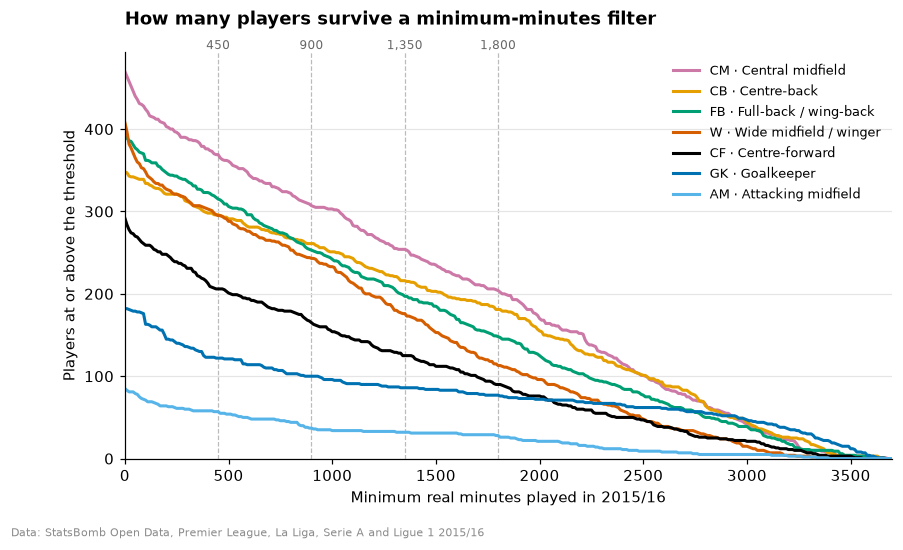

In [5]:
grid = np.arange(0, 3701, 10)
fig, ax = plt.subplots(figsize=(9, 4.8))
remaining = {
    g: [(players.loc[players.position_group == g, "minutes"] >= x).sum() for x in grid]
    for g in GROUPS
}
for g in sorted(GROUPS, key=lambda g: -remaining[g][90]):
    ax.plot(grid, remaining[g], color=COLORS[g], lw=2, label=f"{g} · {GROUP_NAMES[g]}")
for t in THRESHOLDS:
    ax.axvline(t, color="#BBBBBB", lw=0.8, ls="--", zorder=0)
    ax.text(t, ax.get_ylim()[1], f"{t:,}", ha="center", va="bottom", fontsize=8, color="#666666")
ax.set_xlim(0, 3700)
ax.set_ylim(0)
ax.set_xlabel("Minimum real minutes played in 2015/16")
ax.set_ylabel("Players at or above the threshold")
ax.set_title("How many players survive a minimum-minutes filter", pad=18)
ax.legend(loc="upper right", fontsize=8.5)
credit(fig, "Data: StatsBomb Open Data, Premier League, La Liga, Serie A and Ligue 1 2015/16")
plt.show()

### 1.3 How pure are the position groups?

For players with 900 minutes or more: the share of their minutes spent in each group (rows: the
player's primary group). A low diagonal means the group mixes roles.

In [6]:
regulars = players[players.minutes >= 900]
group_cols = [f"minutes_{g.lower()}" for g in GROUPS]
mix = regulars.groupby("position_group", observed=True)[group_cols].sum()
mix = mix.div(mix.sum(axis=1), axis=0).mul(100).round().astype(int)
mix.columns = GROUPS
mix.index = [f"{c} (n={n})" for c, n in regulars.position_group.value_counts()[mix.index].items()]
mix

,GK,CB,FB,CM,AM,W,CF
GK (n=100),100,0,0,0,0,0,0
CB (n=261),0,95,4,1,0,0,0
FB (n=253),0,4,92,1,0,3,0
CM (n=307),0,1,1,90,4,3,0
AM (n=37),0,0,0,13,64,17,6
W (n=243),0,0,2,5,8,78,7
CF (n=165),0,0,0,1,3,7,89


### 1.4 Merging attacking midfield: with the wingers, or split between midfield and attack?

Attacking midfield is too small to compare on its own (37 players at 900 minutes). Two ways to
merge it:

- **Option A:** attacking midfield + wingers ("attacking midfielders and wingers", the grouping
  of StatsBomb's radar templates);
- **Option B:** attacking midfield + central midfield ("midfielders") and wingers +
  centre-forwards ("forwards").

A merge makes sense if the merged players **move between those positions** (test 1) and **do
similar things on the ball** (test 2). Both tests use outfield players with 900 minutes or more.

**Test 1: who swaps positions with whom.** Minutes played across each boundary: minutes that
players of one group spent in the other, both ways (thousands of minutes).

In [7]:
counts = player_match_counts(con)
season = rates(counts.groupby("player_id")[SUMMED].sum())
outfield = players[(players.minutes >= 900) & (players.position_group != "GK")].set_index(
    "player_id"
)
group = outfield.position_group.astype(str)

FOCUS = ["CM", "AM", "W", "CF"]
spent = outfield.groupby(group)[[f"minutes_{g.lower()}" for g in FOCUS]].sum().loc[FOCUS]
spent.columns = FOCUS
across = spent + spent.T  # X players' minutes in Y plus Y players' minutes in X
OPTIONS = {"A": [("AM", "W")], "B": [("AM", "CM"), ("W", "CF")]}
pairs = [("AM", "W"), ("AM", "CM"), ("W", "CF"), ("CM", "W"), ("AM", "CF"), ("CM", "CF")]
pd.DataFrame(
    {
        "minutes across (thousands)": [across.loc[a, b] / 1000 for a, b in pairs],
        "kept inside a group by": [
            " and ".join(o for o, ps in OPTIONS.items() if (a, b) in ps) or "neither"
            for a, b in pairs
        ],
    },
    index=[f"{a} ↔ {b}" for a, b in pairs],
).round(1)

,minutes across (thousands),kept inside a group by
AM ↔ W,50.7,A
AM ↔ CM,33.8,B
W ↔ CF,54.8,B
CM ↔ W,42.2,neither
AM ↔ CF,15.4,neither
CM ↔ CF,4.9,neither


Both options keep a large share of the swaps inside a group: option A the AM ↔ W swaps,
option B the AM ↔ CM and W ↔ CF swaps (more minutes in total, because wingers and
centre-forwards swap a lot in front threes). Seen from attacking midfield, its players spend
17% of their minutes on the wing and 13% in central midfield (table 1.3): a slight lean to
option A, so test 1 alone does not decide.

**Test 2: who plays like whom.** Each player's per-90 profile over 15 on-ball and defensive
actions, standardised across all outfield players (z-scores: 0 is the outfield average, ±1 is
one standard deviation). The map shows each group's average profile.

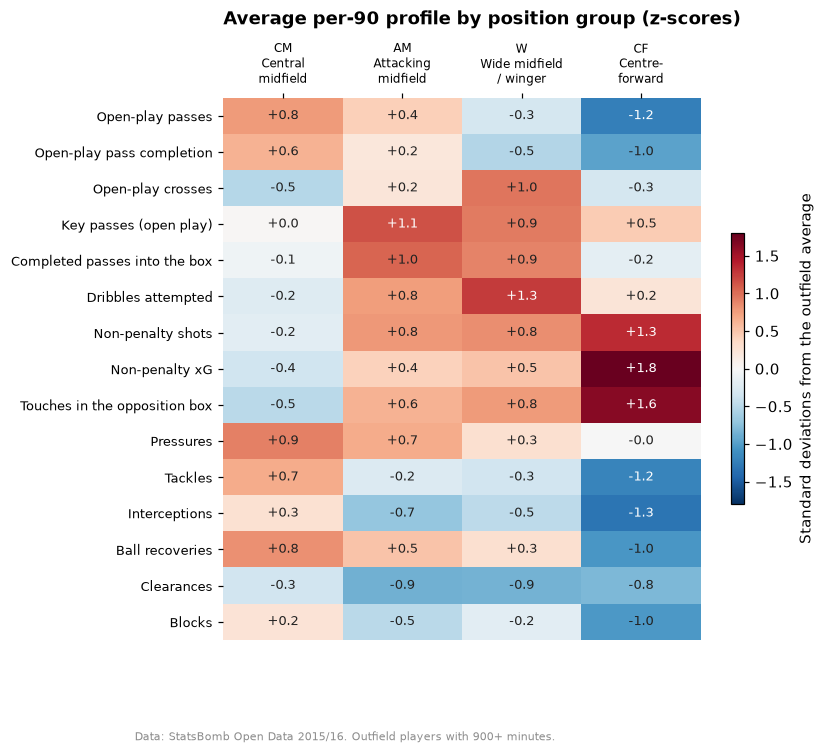

In [8]:
ACTIONS = [
    "passes", "pass_completion", "crosses", "key_passes", "passes_into_box", "dribbles",
    "shots", "xg", "touches_in_box", "pressures", "tackles", "interceptions", "recoveries",
    "clearances", "blocks",
]  # fmt: skip
LOCATION = ["mean_x", "mean_width"]


def zscores(columns: list[str]) -> pd.DataFrame:
    x = season.loc[outfield.index, columns]
    return (x - x.mean()) / x.std()


z = zscores(ACTIONS)
profile = z.groupby(group).mean().loc[FOCUS].T

fig, ax = plt.subplots(figsize=(7, 6.4))
im = ax.imshow(profile, cmap="RdBu_r", vmin=-1.8, vmax=1.8, aspect="auto")
for (r, c), v in np.ndenumerate(profile.to_numpy()):
    ax.text(
        c,
        r,
        f"{v:+.1f}",
        ha="center",
        va="center",
        fontsize=8.5,
        color="white" if abs(v) > 1.1 else "#222222",
    )
SHORT = {
    "CM": "Central\nmidfield",
    "AM": "Attacking\nmidfield",
    "W": "Wide midfield\n/ winger",
    "CF": "Centre-\nforward",
}
ax.set_xticks(range(len(FOCUS)), [f"{g}\n{SHORT[g]}" for g in FOCUS], fontsize=8)
ax.set_yticks(range(len(ACTIONS)), [LABELS[a] for a in ACTIONS], fontsize=8.5)
ax.xaxis.tick_top()
ax.grid(False)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_title("Average per-90 profile by position group (z-scores)", pad=48)
fig.colorbar(im, ax=ax, shrink=0.5, label="Standard deviations from the outfield average")
credit(fig, "Data: StatsBomb Open Data 2015/16. Outfield players with 900+ minutes.")
plt.show()

Three checks on the profiles:

- **distance between group averages** (Euclidean, in standard deviations), with and without
  two location features (average touch position up the pitch and distance from the centre
  line), which do not change the answer;
- **closest group** for each attacking midfielder and each winger, leaving their own group out;
- **spread inside each group** (average distance of its players to the group average) before
  and after each merge: a merge of unlike players widens it.

In [9]:
def distances(z: pd.DataFrame) -> pd.Series:
    c = z.groupby(group).mean()
    return pd.Series({f"{a} – {b}": np.linalg.norm(c.loc[a] - c.loc[b]) for a, b in pairs})


display(
    pd.DataFrame(
        {"actions": distances(z), "actions + location": distances(zscores(ACTIONS + LOCATION))}
    )
    .round(2)
    .rename_axis("distance between")
)

centroids = z.groupby(group).mean()
closest = {}
for g in ["AM", "W"]:
    others = [o for o in FOCUS if o != g]
    d = pd.DataFrame({o: np.linalg.norm(z[group == g] - centroids.loc[o], axis=1) for o in others})
    closest[f"{g} players (n={len(d)})"] = d.idxmin(axis=1).value_counts(normalize=True)
display(
    pd.DataFrame(closest)
    .T.reindex(columns=FOCUS)
    .mul(100)
    .round()
    .fillna(0)
    .astype(int)
    .rename_axis("% closest to")
)

MERGES = {
    "No merge": {},
    "Option A": {"AM": "AM+W", "W": "AM+W"},
    "Option B": {"AM": "AM+CM", "CM": "AM+CM", "W": "W+CF", "CF": "W+CF"},
}
spread = {}
for option, mapping in MERGES.items():
    label = group.replace(mapping)
    spread[option] = z.groupby(label).apply(lambda d: np.linalg.norm(d - d.mean(), axis=1).mean())
pd.DataFrame(spread).round(2).rename_axis("spread inside")

,actions,actions + location
distance between,,
AM – W,1.54,1.77
AM – CM,3.14,3.29
W – CF,3.42,3.60
CM – W,3.85,4.21
AM – CF,3.79,3.83
CM – CF,5.53,5.70


,CM,AM,W,CF
% closest to,,,,
AM players (n=37),16,0,81,3
W players (n=243),9,74,0,16


,No merge,Option A,Option B
spread inside,,,
AM,2.79,NaN,NaN
AM+CM,NaN,NaN,2.87
AM+W,NaN,3.09,NaN
CB,2.02,2.02,2.02
CF,2.45,2.45,NaN
CM,2.72,2.72,NaN
FB,2.51,2.51,2.51
W,3.08,NaN,NaN
W+CF,NaN,NaN,3.28


**Result: option A.** Attacking midfielders play like wingers, not like central midfielders:
the AM and W profiles are 1.5 standard deviations apart, against 3.1 for AM–CM and 3.4 for
W–CF, and 81% of attacking midfielders are closest to the winger profile. Merging AM into W
leaves the winger group's spread unchanged (3.08 → 3.09), while option B widens both merged
groups, most of all the forwards (centre-forwards 2.45 → 3.28): it would rank wingers
against strikers on shots and xG. Wingers and centre-forwards do swap positions often (test
1), but they do different jobs, so they stay apart.

Players are compared within six groups (`comparison_groups` in `config/pipeline.yaml`):
goalkeepers, centre-backs, full-backs, central midfielders, **attacking midfielders and
wingers**, centre-forwards.

### 1.5 By age

Share of players in each minutes band, by age on 30 June 2016. Young players are where a
recruitment back-test has the most to gain, and also where a minutes filter cuts hardest.

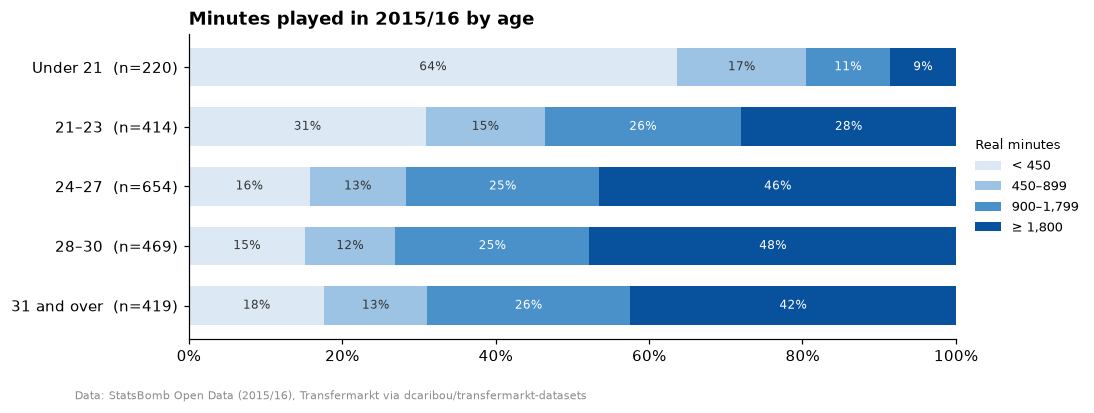

In [10]:
AGE_BANDS = [0, 21, 24, 28, 31, 99]
AGE_LABELS = ["Under 21", "21–23", "24–27", "28–30", "31 and over"]
MINUTE_BANDS = [0, 450, 900, 1800, np.inf]
MINUTE_LABELS = ["< 450", "450–899", "900–1,799", "≥ 1,800"]

aged = players.dropna(subset=["age"]).assign(
    age_band=lambda d: pd.cut(d.age, AGE_BANDS, right=False, labels=AGE_LABELS),
    minutes_band=lambda d: pd.cut(d.minutes, MINUTE_BANDS, right=False, labels=MINUTE_LABELS),
)
shares = pd.crosstab(aged.age_band, aged.minutes_band, normalize="index")
band_sizes = aged.age_band.value_counts().reindex(AGE_LABELS)

fig, ax = plt.subplots(figsize=(9, 3.6))
blues = ["#DCE9F5", "#9CC3E4", "#4A90C9", "#08519C"]
left = np.zeros(len(shares))
for band, colour in zip(MINUTE_LABELS, blues, strict=True):
    ax.barh(range(len(shares)), shares[band], left=left, color=colour, label=band, height=0.65)
    for i, (x0, w) in enumerate(zip(left, shares[band], strict=True)):
        if w >= 0.06:
            text_colour = "white" if band in MINUTE_LABELS[2:] else "#333333"
            ax.text(
                x0 + w / 2, i, f"{w:.0%}", ha="center", va="center", fontsize=8, color=text_colour
            )
    left += shares[band].to_numpy()
ax.set_yticks(range(len(shares)), [f"{a}  (n={band_sizes[a]})" for a in shares.index])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.grid(False)
ax.set_title("Minutes played in 2015/16 by age")
ax.legend(
    title="Real minutes",
    loc="center left",
    bbox_to_anchor=(1.01, 0.5),
    fontsize=8.5,
    title_fontsize=8.5,
    alignment="left",
)
credit(fig)
plt.show()

In [11]:
threshold_table(aged, "age_band")

,players,p25,median,p75,≥ 450,≥ 900,"≥ 1,350","≥ 1,800"
Under 21,220,50,220,770,80 (36%),43 (20%),28 (13%),19 (9%)
21–23,414,300,1010,1950,286 (69%),222 (54%),164 (40%),116 (28%)
24–27,654,810,1670,2550,551 (84%),469 (72%),382 (58%),304 (46%)
28–30,469,840,1720,2450,398 (85%),343 (73%),286 (61%),224 (48%)
31 and over,419,650,1460,2400,345 (82%),289 (69%),226 (54%),178 (42%)


**Where does "young" end?** The same shares by year of age (age in whole years on 30 June 2016):

In [12]:
YEAR_BANDS = [0, 20, 21, 22, 23, 24, 25, 28, 31, 99]
YEAR_LABELS = ["Under 20", "20", "21", "22", "23", "24", "25–27", "28–30", "31 and over"]

by_year = aged.groupby(
    pd.cut(aged.age, YEAR_BANDS, right=False, labels=YEAR_LABELS), observed=True
)["minutes"]
young = aged[aged.age < 23]
print(
    f"Under 23: {len(young)} players, {(young.minutes >= 900).sum()} with 900+ minutes and "
    f"{young.minutes.between(450, 900, inclusive='left').sum()} more with 450–899."
)
pd.DataFrame(
    {
        "players": by_year.size(),
        "≥ 450 minutes": by_year.apply(lambda m: f"{(m >= 450).mean():.0%}"),
        "≥ 900 minutes": by_year.apply(lambda m: f"{(m >= 900).mean():.0%}"),
    }
).T.rename_axis(None, axis=1)

Under 23: 482 players, 175 with 900+ minutes and 70 more with 450–899.


,Under 20,20,21,22,23,24,25–27,28–30,31 and over
players,110,110,121,141,152,151,503,469,419
≥ 450 minutes,29%,44%,57%,68%,80%,80%,85%,85%,82%
≥ 900 minutes,16%,23%,45%,55%,59%,67%,73%,73%,69%


The share of players reaching 900 minutes climbs through the early twenties (23% at 20, 45% at
21, 55% at 22, 59% at 23) and levels off at 67–73% from 24. **Under 23**, also football's usual
young-player limit, marks the players a 900-minute filter treats hardest. Lowering their
threshold to 450 minutes adds 70 players to the 175 under-23s who pass 900.

### 1.6 Players who changed clubs

Summing minutes over clubs only matters for the few players who moved during the season.

In [13]:
moves = players.assign(
    move=np.select(
        [players.n_teams == 1, players.n_leagues == 1],
        ["One club", "Two clubs, same league"],
        "Two clubs, two leagues",
    )
)
pd.DataFrame(
    {
        "players": moves.groupby("move").size(),
        "≥ 900 summed": moves[moves.minutes >= 900].groupby("move").size(),
        "≥ 900 only when summed": moves[(moves.minutes >= 900) & (moves.max_team_minutes < 900)]
        .groupby("move")
        .size(),
    }
).fillna(0).astype(int).rename_axis(None)

,players,≥ 900 summed,≥ 900 only when summed
One club,2073,1289,0
"Two clubs, same league",65,47,8
"Two clubs, two leagues",38,30,5


### 1.7 Can percentiles be computed within each league?

A percentile is only as precise as the group it is computed in. If a player's true standing is
the 80th percentile, the percentile measured among n players has a 95% margin of about
±1.96·√(0.8·0.2/n): ±30 points with 7 players, ±8 with 100. The table counts players with 900
minutes or more per comparison group and league.

In [14]:
regulars = players[players.minutes >= 900]
n = regulars.pivot_table(
    index="comparison_group",
    columns="league",
    values="player_id",
    aggfunc="count",
    observed=True,
)
am_alone = regulars[regulars.position_group == "AM"].groupby("league").size()
n.loc["AM alone (not used)"] = am_alone
n["All four leagues"] = n.sum(axis=1)


def margin(k):
    return 1.96 * np.sqrt(0.8 * 0.2 / k) * 100


leagues_only = n.drop(columns="All four leagues")
samples = pd.DataFrame(
    {
        "smallest league": leagues_only.min(axis=1),
        "± points (smallest league)": margin(leagues_only.min(axis=1)),
        "all four leagues": n["All four leagues"],
        "± points (four leagues)": margin(n["All four leagues"]),
    }
)
display(n.rename_axis(None))
samples.round(0).astype(int).rename_axis(None)

league,La Liga,Ligue 1,Premier League,Serie A,All four leagues
GK,23,27,27,23,100
CB,62,68,61,70,261
FB,66,65,59,63,253
CM,70,77,69,91,307
AMW,81,68,79,52,280
CF,42,38,37,48,165
AM alone (not used),8,9,13,7,37


,smallest league,± points (smallest league),all four leagues,± points (four leagues)
GK,23,16,100,8
CB,61,10,261,5
FB,59,10,253,5
CM,69,9,307,4
AMW,52,11,280,5
CF,37,13,165,6
AM alone (not used),7,30,37,13


Within a single league, goalkeepers (23 to 27 per league) and centre-forwards (37 to 48)
would have percentile margins of ±13 to ±16 points, and attacking midfield alone ±30. Pooling
the four leagues brings every group to ±8 points or better. **Percentiles are computed over the
four leagues together**; section 3 checks whether the leagues can share one scale.

### What section 1 shows

- **The leagues are alike in playing time.** Each has about 540 players who played, with a
  median of about 1,350 minutes. At 900 minutes, 61–65% of each league's players remain, so a
  threshold does not favour any league.
- **The cost of a threshold falls on a few position groups.** Attacking midfield is small and
  mixed (85 players, 37 at 900 minutes, as few as 7 in a league); it plays like the wingers and
  is merged with them (1.4). Goalkeepers split into starters who play almost everything and
  back-ups who barely play.
- **Age is where a threshold cuts hardest.** At 900 minutes, 20% of under-21 players remain
  (43 of 220), against 72% of those aged 24–27, and the share keeps rising until about 23
  (1.5).
- **Mid-season moves barely matter.** 103 players changed clubs within the pool; summing their
  minutes brings 13 more players above 900 minutes.
- **Within-league percentiles would be too coarse** for goalkeepers and centre-forwards (1.7).

**Decisions (2026-10-11):**

1. Players are compared from **900 real minutes**; players **under 23** on 30 June 2016 from
   **450 minutes** (1.5). Small samples are handled by shrinking per-90 numbers towards the
   group average (section 2).
2. Six **comparison groups**, attacking midfield merged with the wingers (1.4).
3. **Percentiles over the four leagues together** (1.7).
4. **Minutes summed over clubs** for players who moved mid-season.
5. Shinji Okazaki, the only pool player without a Transfermarkt date of birth, gets it from a
   public source (`config/date_of_birth_overrides.csv`).

## 2. How many minutes before a per-90 number means something?

A player's per-90 rate mixes skill and chance. **Split-half reliability** measures how much of
it is skill: deal each player's matches at random into two halves of M minutes each and
correlate the two halves' rates across players. A correlation of 1 means the rate is all
player; 0 means it is all chance.

- **Players:** outfield players with 1,800 minutes or more (764), so both halves can reach
  900 minutes. Rates are centred within comparison group and league first, so the test asks
  whether a player stands out from comparable players, not whether strikers shoot more than
  centre-backs (and section 3 shows the leagues record some events differently).
- **Random halves, 50 draws**, not first vs second half of the season: a chronological split
  would mix chance with real change (form, injuries, new coaches).
- **Model:** reliability follows r = M / (M + K) closely. **K is the number of minutes at which a
  rate is half skill, half chance**, and M / (M + K) is the weight a player's own rate deserves
  against the group average after M minutes: the shrinkage rule for small samples.

In [15]:
# The 15 per-90 rates studied here (analysis.metrics also holds those added for the profiles).
RATES_15 = [
    "passes", "crosses", "key_passes", "passes_into_box", "shots", "xg", "goals", "dribbles",
    "touches_in_box", "pressures", "tackles", "interceptions", "recoveries", "clearances",
    "blocks",
]  # fmt: skip
REL_METRICS = [*RATES_15, "pass_completion", "dribble_success"]
MINUTES_GRID = [180, 270, 360, 450, 600, 750, 900]

long_season = players[(players.minutes >= 1800) & (players.comparison_group != "GK")]
context = (long_season.comparison_group.astype(str) + " | " + long_season.league).set_axis(
    long_season.player_id
)
curve = split_half_reliability(
    counts[counts.player_id.isin(long_season.player_id)],
    context,
    REL_METRICS,
    MINUTES_GRID,
    draws=50,
)
K = stabilisation_minutes(curve, REL_METRICS)
mean_curve = curve.groupby("target")[["players", "minutes", *REL_METRICS]].mean()
print(
    f"{len(long_season)} players; {mean_curve.players.min():.0f} reach 900 minutes in both halves."
)

# Model check: if r = M / (M + K) holds, K = M (1 - r) / r is the same at every M.
implied = mean_curve[REL_METRICS].rdiv(1).sub(1).mul(mean_curve.minutes, axis=0)
print(
    "K implied at each M varies by at most "
    f"{(implied.max() / implied.min() - 1).drop('dribble_success').max():.0%} "
    "(dribble success excluded: it is almost pure noise)."
)

764 players; 702 reach 900 minutes in both halves.
K implied at each M varies by at most 10% (dribble success excluded: it is almost pure noise).


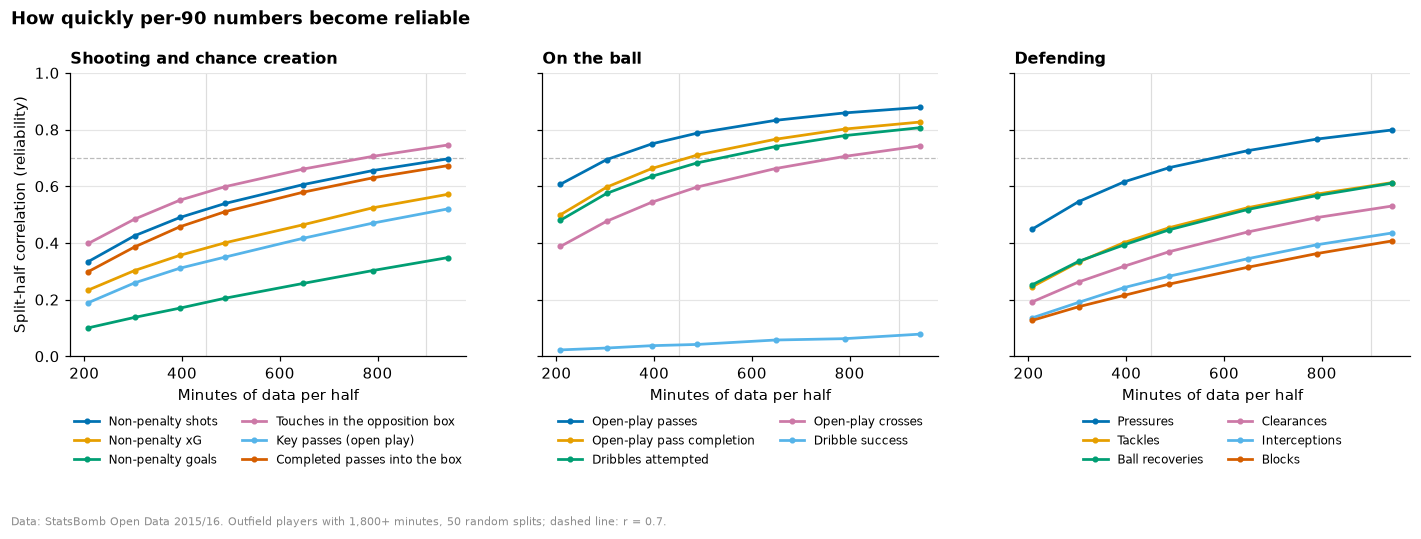

In [16]:
FAMILIES = {
    "Shooting and chance creation": [
        "shots", "xg", "goals", "touches_in_box", "key_passes", "passes_into_box",
    ],
    "On the ball": ["passes", "pass_completion", "dribbles", "crosses", "dribble_success"],
    "Defending": ["pressures", "tackles", "recoveries", "clearances", "interceptions", "blocks"],
}  # fmt: skip

fig, axes = plt.subplots(1, 3, figsize=(13, 4.6), sharey=True)
for ax, (family, metrics) in zip(axes, FAMILIES.items(), strict=True):
    for colour, m in zip(OKABE_ITO, metrics, strict=False):
        ax.plot(
            mean_curve.minutes,
            mean_curve[m],
            marker="o",
            ms=3,
            lw=1.8,
            color=colour,
            label=LABELS[m],
        )
    ax.axhline(0.7, color="#BBBBBB", lw=0.8, ls="--", zorder=0)
    for t in (450, 900):
        ax.axvline(t, color="#DDDDDD", lw=0.8, zorder=0)
    ax.set_title(family, fontsize=10.5)
    ax.set_xlabel("Minutes of data per half")
    ax.set_ylim(0, 1)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), fontsize=8, ncol=2)
axes[0].set_ylabel("Split-half correlation (reliability)")
fig.suptitle(
    "How quickly per-90 numbers become reliable", x=0.01, ha="left", fontweight="bold", fontsize=12
)
credit(
    fig,
    "Data: StatsBomb Open Data 2015/16. Outfield players with 1,800+ minutes, "
    "50 random splits; dashed line: r = 0.7.",
)
fig.tight_layout()
plt.show()

In [17]:
reliability = pd.DataFrame(
    {
        "K: minutes for r = 0.5": K,
        "r at 450 minutes": 450 / (450 + K),
        "r at 900 minutes": 900 / (900 + K),
        "minutes for r = 0.7": minutes_for(0.7, K),
    }
).sort_values("K: minutes for r = 0.5")
reliability.index = [LABELS[m] for m in reliability.index]
reliability.round(
    {
        "K: minutes for r = 0.5": -1,
        "r at 450 minutes": 2,
        "r at 900 minutes": 2,
        "minutes for r = 0.7": -1,
    }
)

,K: minutes for r = 0.5,r at 450 minutes,r at 900 minutes,minutes for r = 0.7
Open-play passes,130.0,0.77,0.87,310.0
Open-play pass completion,200.0,0.69,0.82,470.0
Dribbles attempted,230.0,0.67,0.80,530.0
Pressures,250.0,0.65,0.78,580.0
Touches in the opposition box,320.0,0.58,0.74,760.0
Open-play crosses,330.0,0.58,0.73,770.0
Non-penalty shots,410.0,0.52,0.68,970.0
Completed passes into the box,470.0,0.49,0.66,1100.0
Tackles,600.0,0.43,0.60,1390.0
Ball recoveries,610.0,0.43,0.60,1410.0


### What section 2 shows

- **Volume and style numbers settle fast.** Passes (K ≈ 130 minutes), pass completion,
  dribbles and pressures are about 80% reliable at 900 minutes and two-thirds reliable at 450.
- **The numbers scouts care most about settle slowly.** At 900 minutes non-penalty xG is about
  0.56 reliable and key passes 0.50; reaching 0.7 takes about 1,700 and 2,100 minutes.
- **Goals are mostly chance over one season** (0.33 at 900 minutes; 4,000+ minutes for 0.7),
  which is why xG, not goals, should rank finishers' output. **Dribble success rate is almost
  pure noise** (0.08 at 900 minutes) and should not rank players.
- **Interceptions and blocks** are weakly reliable even at 900 minutes (about 0.4), partly
  because of how they are recorded (section 3).

So the 900-minute filter does not make every number trustworthy on its own: below about
r = 0.7, a raw per-90 rank rewards luck. **Shrinking each rate towards the comparison group's
average with weight M / (M + K)**, metric by metric, uses the table above directly.

**Decisions (2026-10-11):**

1. **Every player's** per-90 rates and ratios are shrunk towards the comparison group's average
   with weight M / (M + K), using each metric's K from the table above. Regulars included: at
   900 minutes, xG and key passes are still about half chance.
2. **Goals and dribble success rate do not rank players.** Non-penalty xG stands in for goals.

## 3. Do the four leagues play, and get recorded, the same way?

Pooling the leagues (section 1.7) assumes a per-90 number means the same in each. Two things
can break that: **style** (a league that presses more gives every player more pressures) and
**recording** (if events are coded differently, numbers differ with no football reason).

### 3.1 Team numbers per league

Per team and match, per 90 real minutes of match. η² is the share of the variation between
team-matches explained by the league (0 = none).

In [18]:
team = (
    counts.groupby(["match_id", "competition_id", "team_id"])[SUMMED].sum().reset_index()
    .merge(con.sql("""
        SELECT m.match_id, m.duration_seconds / 60 AS match_minutes, c.competition_name AS league
        FROM matches m JOIN competitions c USING (competition_id, season_id)
        WHERE m.scouting_pool""").df(), on="match_id")
    .merge(con.sql("SELECT match_id, team_id, count(*) AS fouls FROM fouls_committed GROUP BY ALL")
           .df(), on=["match_id", "team_id"], how="left")
    .fillna({"fouls": 0})
)  # fmt: skip
TEAM_METRICS = {
    "match_minutes": "Match length (real minutes)",
    "passes": "Open-play passes",
    "pass_completion": "Open-play pass completion",
    "pressures": "Pressures",
    "shots": "Non-penalty shots",
    "xg": "Non-penalty xG",
    "goals": "Non-penalty goals",
    "dribbles": "Dribbles attempted",
    "crosses": "Open-play crosses",
    "tackles": "Tackles",
    "interceptions": "Interceptions",
    "clearances": "Clearances",
    "fouls": "Fouls committed",
}
team["pass_completion"] = team.passes_completed / team.passes  # before rescaling passes
for m in TEAM_METRICS:
    if m not in ("match_minutes", "pass_completion"):
        team[m] = team[m] / team.match_minutes * 90


by_league = team.groupby("league")[list(TEAM_METRICS)].mean().T
by_league["All four"] = team[list(TEAM_METRICS)].mean()
by_league["η²"] = [eta_squared(team[m], team.league) for m in TEAM_METRICS]
by_league.index = TEAM_METRICS.values()
by_league.round(3)

league,La Liga,Ligue 1,Premier League,Serie A,All four,η²
Match length (real minutes),94.124,94.865,96.414,95.261,95.167,0.213
Open-play passes,408.213,419.800,405.216,412.895,411.515,0.003
Open-play pass completion,0.750,0.765,0.762,0.764,0.760,0.009
Pressures,143.598,164.551,141.853,162.755,153.167,0.077
Non-penalty shots,11.415,10.980,12.055,12.288,11.686,0.012
Non-penalty xG,1.138,1.012,1.105,1.028,1.071,0.007
Non-penalty goals,1.191,1.075,1.121,1.069,1.114,0.002
Dribbles attempted,18.313,15.549,16.861,14.545,16.318,0.060
Open-play crosses,11.071,10.511,10.713,11.067,10.841,0.002
Tackles,18.934,19.816,18.979,17.345,18.766,0.028


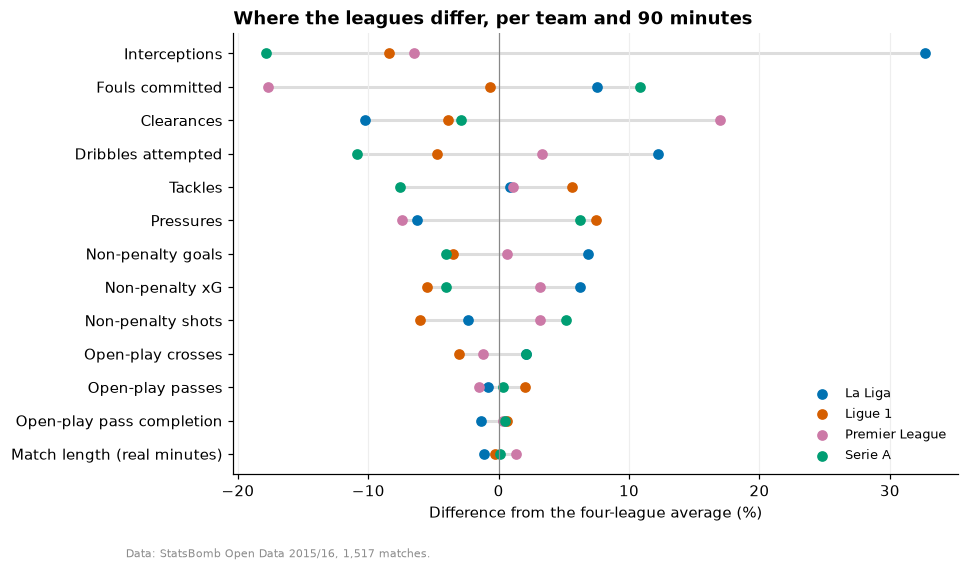

In [19]:
LEAGUES = sorted(team.league.unique())
LEAGUE_COLORS = dict(
    zip(LEAGUES, [OKABE_ITO[0], OKABE_ITO[5], OKABE_ITO[3], OKABE_ITO[2]], strict=True)
)
diff = by_league[LEAGUES].div(by_league["All four"], axis=0).sub(1).mul(100)
order = diff.abs().max(axis=1).sort_values().index

fig, ax = plt.subplots(figsize=(8.5, 5.2))
for i, metric in enumerate(order):
    ax.plot(
        [diff.loc[metric].min(), diff.loc[metric].max()], [i, i], color="#DDDDDD", lw=2, zorder=1
    )
for league in LEAGUES:
    ax.scatter(
        diff.loc[order, league],
        range(len(order)),
        color=LEAGUE_COLORS[league],
        s=36,
        label=league,
        zorder=2,
    )
ax.axvline(0, color="#888888", lw=0.8)
ax.set_yticks(range(len(order)), order)
ax.grid(axis="x", color="#EEEEEE")
ax.grid(axis="y", visible=False)
ax.set_xlabel("Difference from the four-league average (%)")
ax.set_title("Where the leagues differ, per team and 90 minutes")
ax.legend(loc="lower right", fontsize=8.5)
credit(fig, "Data: StatsBomb Open Data 2015/16, 1,517 matches.")
plt.show()

### 3.2 A change in how the Premier League was recorded

Interceptions differ far more between leagues than anything else, which is unlikely to be
football. Tracking event counts match week by match week shows why: from **28 December 2015**
(match week 19) the Premier League records about three times as many interceptions per match
and about 18% more pressures, while passes, ball recoveries and duels stay flat. Nothing on the
pitch changes that abruptly; the way the data was collected did.

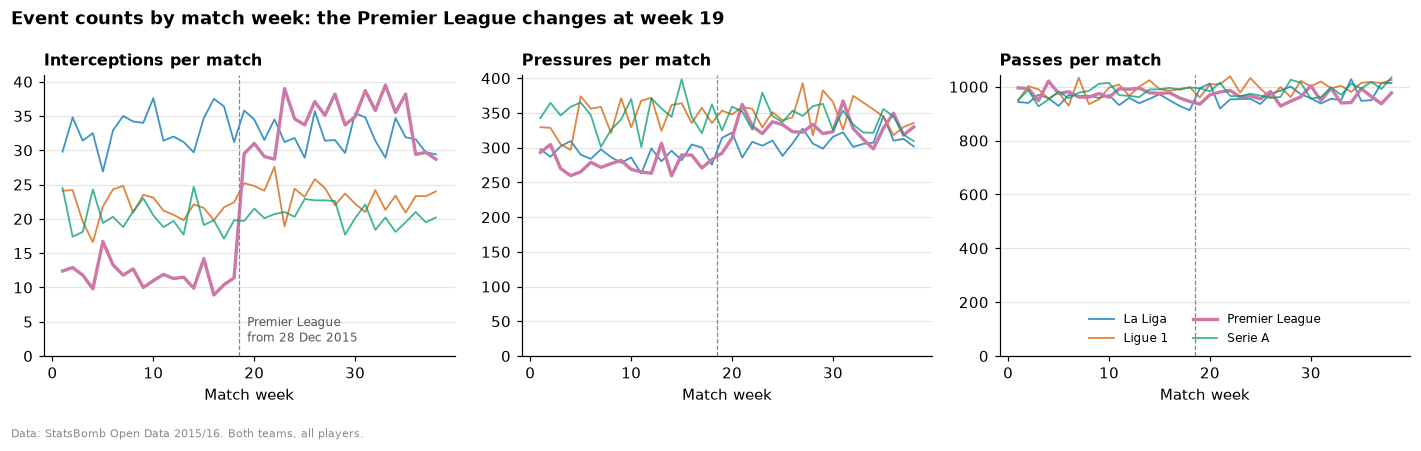

In [20]:
weekly = con.sql("""
    SELECT c.competition_name AS league, m.match_week, count(DISTINCT m.match_id) AS matches,
           count(*) FILTER (WHERE e.type = 'Interception') AS interceptions,
           count(*) FILTER (WHERE e.type = 'Pressure') AS pressures,
           count(*) FILTER (WHERE e.type = 'Pass') AS passes
    FROM matches m
    JOIN competitions c ON c.competition_id = m.competition_id
    JOIN events e ON e.match_id = m.match_id
    WHERE m.scouting_pool
    GROUP BY ALL ORDER BY ALL
""").df()
for m in ("interceptions", "pressures", "passes"):
    weekly[m] = weekly[m] / weekly.matches

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, m in zip(axes, ["interceptions", "pressures", "passes"], strict=True):
    for league in LEAGUES:
        w = weekly[weekly.league == league]
        ax.plot(
            w.match_week,
            w[m],
            color=LEAGUE_COLORS[league],
            label=league,
            lw=2.2 if league == "Premier League" else 1.2,
            alpha=1 if league == "Premier League" else 0.75,
        )
    ax.axvline(18.5, color="#888888", lw=0.8, ls="--")
    ax.set_title(f"{m.capitalize()} per match", fontsize=10.5)
    ax.set_xlabel("Match week")
    ax.set_ylim(0)
axes[0].text(
    19.3, 1.5, "Premier League\nfrom 28 Dec 2015", fontsize=8, va="bottom", color="#555555"
)
axes[2].legend(fontsize=8, loc="lower center", ncol=2)
fig.suptitle(
    "Event counts by match week: the Premier League changes at week 19",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=12,
)
credit(fig, "Data: StatsBomb Open Data 2015/16. Both teams, all players.")
fig.tight_layout()
plt.show()

The same comparison (match weeks 19–38 against 1–18) for every event type in every
league: outside the Premier League, no event type moves by more than 8%.

In [21]:
screen = (
    con.sql("""
    WITH per AS (
        SELECT c.competition_name AS league, m.match_id, m.match_week, e.type, count(*) AS n
        FROM events e
        JOIN matches m ON m.match_id = e.match_id
        JOIN competitions c ON c.competition_id = m.competition_id
        WHERE m.scouting_pool GROUP BY ALL),
    grid AS (
        SELECT g.league, g.match_id, g.match_week, t.type
        FROM (SELECT DISTINCT league, match_id, match_week FROM per) g
        CROSS JOIN (SELECT DISTINCT type FROM per) t),
    filled AS (
        SELECT grid.*, coalesce(per.n, 0) AS n
        FROM grid LEFT JOIN per USING (league, match_id, type))
    SELECT league, type AS event_type,
           avg(n) FILTER (WHERE match_week <= 18) AS weeks_1_18,
           avg(n) FILTER (WHERE match_week >= 19) AS weeks_19_38
    FROM filled GROUP BY ALL HAVING avg(n) >= 5 ORDER BY league, event_type
""")
    .df()
    .assign(ratio=lambda d: d.weeks_19_38 / d.weeks_1_18)
)
screen.reindex(screen.ratio.sub(1).abs().sort_values(ascending=False).index).head(8).round(2)

,league,event_type,weeks_1_18,weeks_19_38,ratio
49,Premier League,Interception,11.77,34.01,2.89
52,Premier League,Pressure,277.62,327.15,1.18
41,Premier League,Clearance,52.49,60.98,1.16
50,Premier League,Miscontrol,26.85,29.76,1.11
31,Ligue 1,Interception,21.78,23.41,1.07
21,Ligue 1,Block,37.53,40.25,1.07
15,La Liga,Pressure,289.86,309.53,1.07
18,Ligue 1,50/50,5.19,5.52,1.06


### 3.3 How much does the league matter for players?

For outfield players with 900 minutes or more: the share of the variation in each per-90 rate
that the league explains once the comparison group is accounted for (partial η²), and how far
each league sits from the average within the same group.

In [22]:
regular_out = players[(players.minutes >= 900) & (players.comparison_group != "GK")]
player_rates = season.loc[regular_out.player_id].assign(
    league=regular_out.league.to_numpy(), group=regular_out.comparison_group.astype(str).to_numpy()
)


PLAYER_METRICS = [*RATES_15, "pass_completion"]
effects = pd.DataFrame({LABELS[m]: league_effect(player_rates, m) for m in PLAYER_METRICS}).T
effects.sort_values("partial η²", ascending=False).round(
    {"partial η²": 3, **dict.fromkeys(LEAGUES, 1)}
)

,partial η²,La Liga,Ligue 1,Premier League,Serie A
Interceptions,0.245,37.0,-9.8,-7.0,-20.4
Pressures,0.080,-6.5,7.1,-8.1,7.1
Clearances,0.080,-7.2,-3.5,18.7,-7.0
Key passes (open play),0.028,-5.7,-8.4,1.7,12.2
Tackles,0.022,2.4,5.6,1.1,-8.9
Blocks,0.021,-4.3,-0.5,-1.7,6.3
Ball recoveries,0.018,-4.0,4.6,-1.7,1.1
Non-penalty shots,0.016,-5.8,-4.5,1.8,8.4
Open-play crosses,0.013,-3.0,-0.9,-8.1,11.6
Touches in the opposition box,0.013,1.6,-7.8,5.9,0.5


### What section 3 shows

- **Attacking output is on one scale.** Once the comparison group is accounted for, the league
  explains almost nothing of a player's non-penalty xG, goals or passes (partial η² ≤ 0.004)
  and little of shots, key passes, crosses or touches in the box (≤ 0.03).
- **Some differences are style.** Pressures run 6–7% above average in Ligue 1 and Serie A and
  6–8% below in La Liga and the Premier League; the Premier League commits 18% fewer fouls
  and makes more clearances; La Liga attempts more dribbles; matches last longest in England
  (96.4 real minutes against 94.1 in Spain).
- **Some differences are recording.** Interceptions per team and match range from 10 (Serie A)
  to 16 (La Liga), and the Premier League's triple from 28 December 2015, together with 18%
  more pressures and 16% more clearances. League explains 25% of the variation in players'
  interceptions. A Premier League player's interceptions, pressures and clearances depend on
  which half of the season the player played in.

Defensive numbers (interceptions above all, then pressures and clearances) are not comparable
across leagues, or within the Premier League across the season, without an adjustment.

**Decision (2026-10-11):** interceptions, pressures and clearances are compared only among
players recorded the same way. There are five recording contexts: La Liga, Serie A, Ligue 1,
and the Premier League before and from 28 December 2015. Within each comparison group, a
player's counts in each context are rescaled so that the context's group average equals the
four-league average; the two parts of a Premier League player's season are rescaled
separately. This also removes real league differences in these three numbers (pressing
intensity, for instance), which cannot be told apart from recording. Attacking and passing
numbers are used as recorded.

## 4. What was a player worth at the end of 2015/16?

The back-test needs two things from Transfermarkt: **the market's view of each player at the end
of the season**, which a recommendation is compared with, and **the values that followed**,
which say how the player's career went. Transfermarkt values are estimates by its community,
published in batches a few times a year, so a player's value "on date X" is the latest valuation
on or before X, and that valuation can be months old.

In [23]:
valuations = pool_valuations(con)
valuations["league"] = valuations.player_id.map(players.set_index("player_id").league)
last_matchday = (
    con.sql("""
    SELECT c.competition_name AS league, max(m.match_date) AS last_matchday
    FROM matches m JOIN competitions c USING (competition_id, season_id)
    WHERE m.scouting_pool GROUP BY ALL ORDER BY league
""")
    .df()
    .set_index("league")
    .last_matchday
)
SEASON_OVER = pd.Timestamp(last_matchday.max())

print(
    f"{valuations.player_id.nunique():,} of {len(players):,} pool players have a valuation "
    f"({len(valuations):,} valuations, {valuations.date.min():%Y} to {valuations.date.max():%Y})."
)
print(
    "Last matchday: "
    + ", ".join(
        f"{league} {d:%-d %B}" for league, d in last_matchday.sort_values(kind="stable").items()
    )
    + "."
)

2,175 of 2,176 pool players have a valuation (65,769 valuations, 2004 to 2026).
Last matchday: Ligue 1 14 May, La Liga 15 May, Serie A 15 May, Premier League 17 May.


### 4.1 When does Transfermarkt revalue players?

Valuations of pool players per day in 2016, by the player's league.

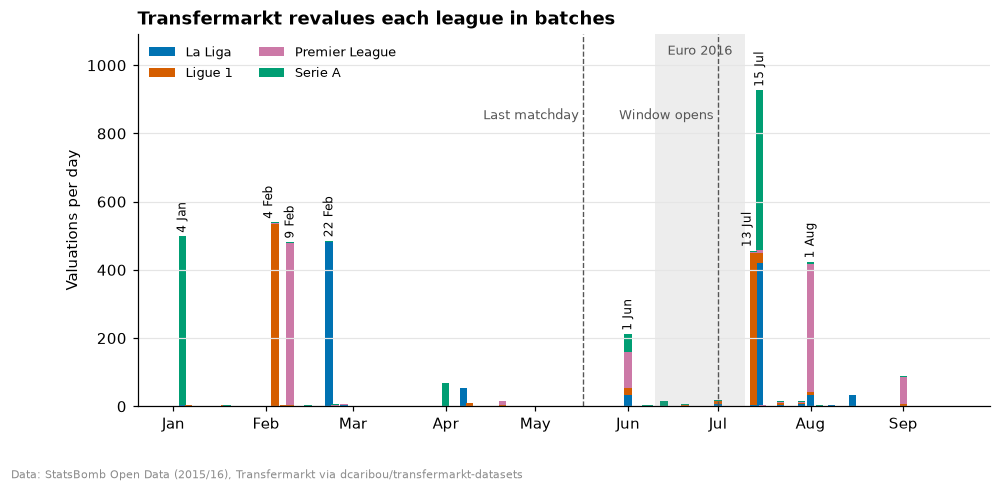

In [24]:
daily = (
    valuations[valuations.date.between("2016-01-01", "2016-09-30")]
    .groupby(["date", "league"])
    .size()
    .unstack(fill_value=0)[LEAGUES]
)
fig, ax = plt.subplots(figsize=(10, 4.4))
bottom = np.zeros(len(daily))
for league in LEAGUES:
    ax.bar(
        daily.index,
        daily[league],
        bottom=bottom,
        width=2.5,
        color=LEAGUE_COLORS[league],
        label=league,
    )
    bottom += daily[league].to_numpy()
top = daily.sum(axis=1).max() * 1.18
ax.axvspan(pd.Timestamp("2016-06-10"), pd.Timestamp("2016-07-10"), color=GREY, alpha=0.15, lw=0)
ax.text(
    pd.Timestamp("2016-06-25"),
    top * 0.97,
    "Euro 2016",
    ha="center",
    va="top",
    fontsize=8.5,
    color="#555555",
)
for day, label in [(SEASON_OVER, "Last matchday"), (pd.Timestamp("2016-07-01"), "Window opens")]:
    ax.axvline(day, color="#555555", lw=0.9, ls="--")
    ax.text(day, top * 0.80, label + " ", ha="right", va="top", fontsize=8.5, color="#555555")
big = daily.sum(axis=1)[lambda s: s >= 100]
for k, (day, n) in enumerate(big.items()):
    # Vertical labels; one followed by another batch within days moves left of its bar.
    crowded = k < len(big) - 1 and (big.index[k + 1] - day).days <= 6
    ax.text(
        day,
        n + top * 0.01,
        f"{day:%-d %b}",
        ha="right" if crowded else "center",
        va="bottom",
        rotation=90,
        fontsize=8,
    )
ax.set_ylim(0, top)
ax.set_xlim(pd.Timestamp("2015-12-20"), pd.Timestamp("2016-09-30"))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_ylabel("Valuations per day")
ax.set_title("Transfermarkt revalues each league in batches")
ax.legend(loc="upper left", fontsize=8.5, ncols=2)
credit(fig)
plt.show()

Every summer since 2015, the dates on which Transfermarkt revalued 100 or more pool players
between May and September (players in the batch in brackets):

In [25]:
summer = valuations[
    valuations.date.dt.month.between(5, 9) & valuations.date.dt.year.between(2015, 2022)
]
batches = summer.groupby("date").size()[lambda s: s >= 100]
batches.groupby(batches.index.year).apply(
    lambda s: ", ".join(f"{day:%-d %b} ({n})" for day, n in s.items())
).rename_axis("summer").to_frame("batches of 100+ valuations")

,batches of 100+ valuations
summer,
2015,"6 Jun (412), 1 Jul (1250), 6 Sep (158)"
2016,"1 Jun (211), 13 Jul (456), 15 Jul (926), 1 Aug..."
2017,"1 Jun (354), 5 Jun (350), 8 Jun (335), 9 Jun (..."
2018,"28 May (329), 30 May (394), 4 Jun (260), 7 Jun..."
2019,"3 Jun (214), 5 Jun (108), 6 Jun (274), 11 Jun ..."
2020,25 Aug (240)
2021,"3 Jun (200), 4 Jun (135), 8 Jun (148), 10 Jun ..."
2022,"30 May (121), 3 Jun (181), 7 Jun (183), 15 Jun..."


**In 2016 the end-of-season revaluation came late.** During the season each league was
revalued once in winter (Serie A on 4 January, Ligue 1 on 4 February, the Premier League on 9
February, La Liga on 22 February). The end-of-season revaluation followed only after Euro 2016
and into the transfer window: Ligue 1 on 13 July, La Liga and Serie A on 15 July, the Premier
League on 1 August. In every later summer it came in late May or June (August in 2020, the
season delayed by COVID-19).

**One batch was different: 1 June 2016**, ten days before the Euro. Almost every player in it
comes from one of the 24 nations at the tournament, and no nation has more than 23 players,
the squad size: it is the pre-tournament revaluation of the Euro squads.

In [26]:
EURO_2016 = [
    "Albania", "Austria", "Belgium", "Croatia", "Czech Republic", "England", "France", "Germany",
    "Hungary", "Iceland", "Ireland", "Italy", "Northern Ireland", "Poland", "Portugal", "Romania",
    "Russia", "Slovakia", "Spain", "Sweden", "Switzerland", "Turkey", "Ukraine", "Wales",
]  # fmt: skip
nationality = (
    con.sql("""
    SELECT m.sb_player_id AS player_id, p.country_of_citizenship AS nationality
    FROM player_map m JOIN tm_players p ON p.player_id = m.tm_player_id
""")
    .df()
    .set_index("player_id")
    .nationality
)
euro_squads = valuations.loc[valuations.date == "2016-06-01", "player_id"]
squad_nations = nationality.reindex(euro_squads)
print(
    f"Revalued on 1 June 2016: {len(euro_squads)} players, "
    f"{squad_nations.isin(EURO_2016).mean():.1%} from the 24 Euro 2016 nations."
)
squad_nations.value_counts().head(10).to_frame("players").T.rename_axis(None, axis=1)

Revalued on 1 June 2016: 211 players, 99.5% from the 24 Euro 2016 nations.


,Italy,France,England,Spain,Belgium,Wales,Croatia,Ireland,Portugal,Poland
players,23,22,22,20,15,13,13,12,10,9


One player shows everything at once. N'Golo Kanté was valued at €10M in Leicester's February
batch, revalued with the France squad on 1 June, and revalued again on 1 August, by then a
Chelsea player (he signed on 16 July):

In [27]:
kante = players.loc[players.player_name.str.contains("Kanté"), "player_id"].item()
valuations.loc[
    (valuations.player_id == kante) & valuations.date.between("2016-01-01", "2016-12-31"),
    ["date", "value", "club"],
].assign(date=lambda d: d.date.dt.strftime("%-d %b %Y"), value=lambda d: d.value / 1e6).rename(
    columns={"value": "value (€M)"}
).set_index("date").rename_axis(None)

,value (€M),club
9 Feb 2016,10.0,Leicester City
1 Jun 2016,20.0,Leicester City
1 Aug 2016,30.0,Chelsea FC


### 4.2 What each cutoff date sees

For candidate cutoff dates: how many players have a value, how old that value is, how many
values were set after the season ended (after the last matchday, 17 May), and how many players
are already valued at a different club than on 30 June.

In [28]:
CUTOFFS = ["2016-05-31", "2016-06-30", "2016-07-16", "2016-08-01"]
june_30 = value_at(valuations, "2016-06-30")
cutoffs = {}
for day in CUTOFFS:
    x = value_at(valuations, day)
    club_before = june_30.club.reindex(x.index)
    cutoffs[f"{pd.Timestamp(day):%-d %b %Y}"] = {
        "players with a value": len(x),
        "median age of the value (days)": x.age_days.median(),
        "value set after the season (%)": x.date.gt(SEASON_OVER).mean() * 100,
        "at another club than on 30 June (%)": (club_before.notna() & x.club.ne(club_before)).mean()
        * 100,
    }
pd.DataFrame(cutoffs).round(0).astype(int)

,31 May 2016,30 Jun 2016,16 Jul 2016,1 Aug 2016
players with a value,2120,2120,2131,2144
median age of the value (days),112,142,3,17
value set after the season (%),0,12,73,89
at another club than on 30 June (%),1,0,15,19


On 30 June, seven players in eight still carry a value set before the season ended, in most
cases the winter one: about five months old, before the second half of the season. The other
one in eight, mostly the Euro squads, had been revalued after the season. On 1 August nearly
nine values in ten postdate the season, but by then about one player in five is valued at
another club.

### 4.3 What the end-of-season revaluation adds

Players revalued between 30 June and 1 August, split three ways: Euro squad players (their
second revaluation, after the tournament), players revalued at another club, and the rest. For
the rest, the change in value by minutes played in 2015/16:

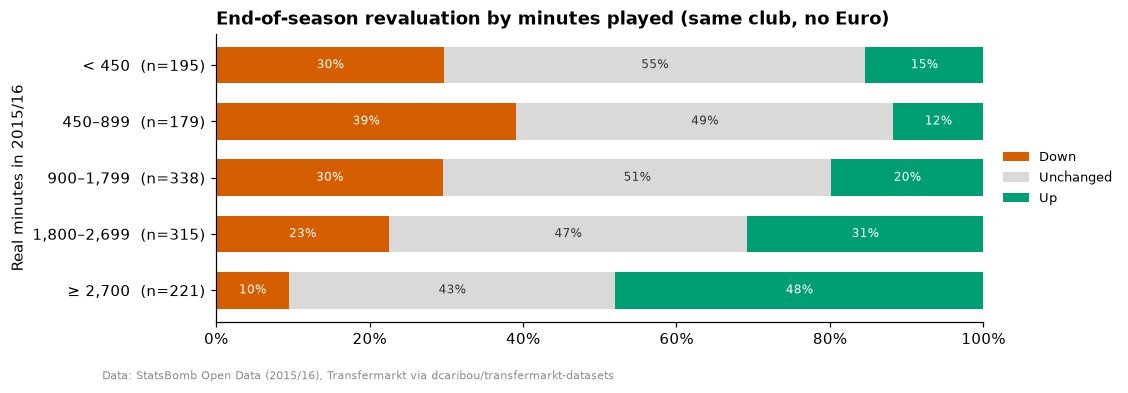

Revalued between 30 June and 1 August: 1,840 of 2,120.
- same club, no Euro: 1248 players, 26% up, 26% down, mean change +3%; Spearman with minutes 0.26
- Euro squads, after the tournament: 199 players, 28% up, 5% down, mean change +5%
- at another club: 415 players, 23% up, 37% down, mean change +0%; 310 of them were last valued after the January window closed, 8 are now without a club


In [29]:
aug_1 = value_at(valuations, "2016-08-01")
summer_change = june_30[["value", "date", "club"]].join(
    aug_1[["value", "date", "club"]], rsuffix="_aug", how="inner"
)
summer_change = summer_change[summer_change.date_aug > summer_change.date]
summer_change["change"] = np.log(summer_change.value_aug / summer_change.value)
summer_change["moved"] = summer_change.club_aug != summer_change.club
summer_change["euro"] = summer_change.index.isin(euro_squads)
stayed = summer_change[~summer_change.moved & ~summer_change.euro].join(
    players.set_index("player_id").minutes
)
direction = np.sign(stayed.change).map({-1.0: "Down", 0.0: "Unchanged", 1.0: "Up"})
minutes_band = pd.cut(
    stayed.minutes,
    [0, 450, 900, 1800, 2700, np.inf],
    right=False,
    labels=["< 450", "450–899", "900–1,799", "1,800–2,699", "≥ 2,700"],
)
moves = pd.crosstab(minutes_band, direction, normalize="index")[["Down", "Unchanged", "Up"]]
band_n = minutes_band.value_counts().reindex(moves.index)

fig, ax = plt.subplots(figsize=(9, 3.4))
left = np.zeros(len(moves))
for col, colour in zip(moves.columns, [OKABE_ITO[5], "#D9D9D9", OKABE_ITO[2]], strict=True):
    ax.barh(range(len(moves)), moves[col], left=left, color=colour, label=col, height=0.65)
    for i, (x0, w) in enumerate(zip(left, moves[col], strict=True)):
        if w >= 0.06:
            text_colour = "#333333" if col == "Unchanged" else "white"
            ax.text(
                x0 + w / 2, i, f"{w:.0%}", ha="center", va="center", fontsize=8, color=text_colour
            )
    left += moves[col].to_numpy()
ax.set_yticks(range(len(moves)), [f"{b}  (n={band_n[b]})" for b in moves.index])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.grid(False)
ax.set_ylabel("Real minutes in 2015/16")
ax.set_title("End-of-season revaluation by minutes played (same club, no Euro)")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8.5)
credit(fig)
plt.show()


def summary(x: pd.Series) -> str:
    return (
        f"{len(x)} players, {(x > 0).mean():.0%} up, {(x < 0).mean():.0%} down, "
        f"mean change {np.exp(x.mean()) - 1:+.0%}"
    )


moved = summer_change[summer_change.moved]
print(f"Revalued between 30 June and 1 August: {len(summer_change):,} of {len(june_30):,}.")
rho = spearmanr(stayed.minutes, stayed.change).statistic
print(f"- same club, no Euro: {summary(stayed.change)}; Spearman with minutes {rho:.2f}")
print(f"- Euro squads, after the tournament: {summary(summer_change[summer_change.euro].change)}")
print(
    f"- at another club: {summary(moved.change)}; {(moved.date > '2016-02-01').sum()} of them "
    f"were last valued after the January window closed, "
    f"{(moved.club_aug == 'Without Club').sum()} are now without a club"
)

The end-of-season revaluation **reacts to the season just played**: among players who stayed
at their club, regulars were revalued up far more often than down, and players who barely
played the other way round. Transfermarkt's winter values therefore lag what a full season of
data shows. The Euro squads' second revaluation, after the tournament, moved them up on
average, and the players already at a new club carry their transfer, loan return or release
in their value.

### 4.4 Values at the end of the season

Values on 30 June 2016 (the picture on 1 August is the same), by age and by comparison group
and league.

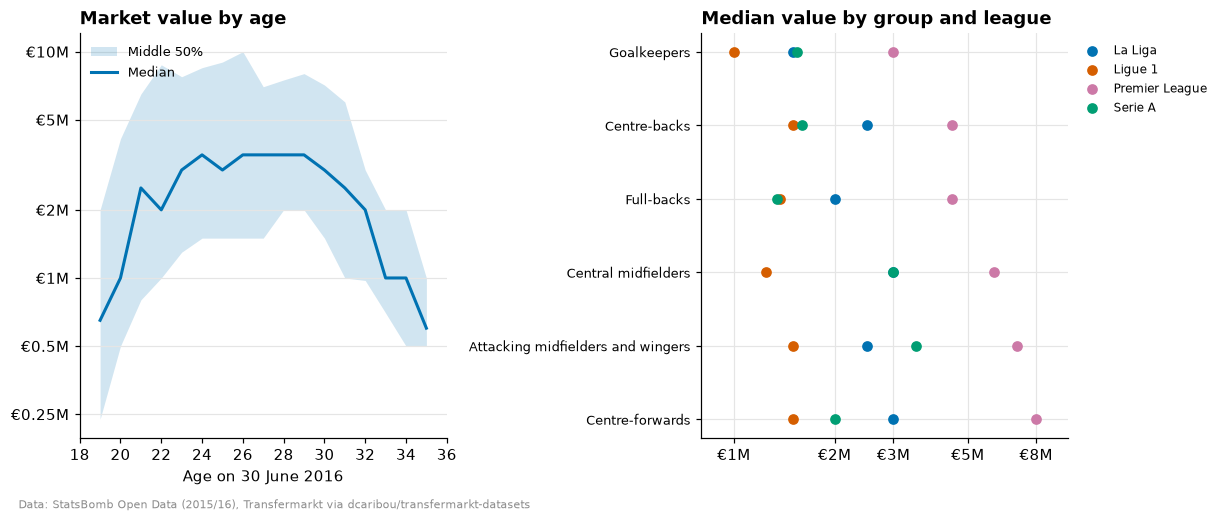

,All players,Goalkeepers,Centre-backs,Full-backs,Central midfielders,Attacking midfielders and wingers,Centre-forwards
"Spearman correlation, value vs minutes",0.48,0.55,0.39,0.52,0.46,0.58,0.52


,players,median (€M),75th percentile (€M)
La Liga,512,2.5,5.25
Ligue 1,558,1.5,2.50
Premier League,509,5.5,11.00
Serie A,541,2.0,6.00


In [30]:
worth = players.set_index("player_id").join(june_30.value, how="inner")
worth["age_years"] = worth.age.floordiv(1)
common_ages = worth.age_years.value_counts()[lambda n: n >= 30].index  # 30+ players per age
by_age = (
    worth[worth.age_years.isin(common_ages)]
    .groupby("age_years")
    .value.quantile([0.25, 0.5, 0.75])
    .unstack()
)
by_group = worth.pivot_table(
    index="comparison_group", columns="league", values="value", aggfunc="median", observed=True
)
euros = FuncFormatter(lambda x, _: f"€{x / 1e6:g}M")


def money_axis(axis, ticks_m):
    axis.set_major_locator(FixedLocator([t * 1e6 for t in ticks_m]))
    axis.set_minor_locator(NullLocator())
    axis.set_major_formatter(euros)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4), width_ratios=[1, 1], layout="constrained")
ax1.fill_between(
    by_age.index,
    by_age[0.25],
    by_age[0.75],
    color=OKABE_ITO[0],
    alpha=0.18,
    lw=0,
    label="Middle 50%",
)
ax1.plot(by_age.index, by_age[0.5], color=OKABE_ITO[0], lw=2, label="Median")
ax1.set_yscale("log")
money_axis(ax1.yaxis, [0.25, 0.5, 1, 2, 5, 10])
ax1.set_xticks(range(18, 37, 2))
ax1.set_xlabel("Age on 30 June 2016")
ax1.set_title("Market value by age")
ax1.legend(loc="upper left", fontsize=8.5)
ys = np.arange(len(by_group))
for league in LEAGUES:
    ax2.scatter(by_group[league], ys, color=LEAGUE_COLORS[league], s=36, label=league, zorder=3)
ax2.set_yticks(ys, [COMPARISON_NAMES[g] for g in by_group.index], fontsize=8.5)
ax2.invert_yaxis()
ax2.set_xscale("log")
ax2.set_xlim(0.8e6, 10e6)
money_axis(ax2.xaxis, [1, 2, 3, 5, 8])
ax2.grid(axis="x")
ax2.set_title("Median value by group and league")
ax2.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8)
credit(fig)
plt.show()

value_minutes = {"All players": spearmanr(worth.value, worth.minutes).statistic}
for g, d in worth.groupby("comparison_group", observed=True):
    value_minutes[COMPARISON_NAMES[g]] = spearmanr(d.value, d.minutes).statistic
display(
    pd.Series(value_minutes, name="Spearman correlation, value vs minutes").round(2).to_frame().T
)
pd.DataFrame(
    {
        "players": worth.groupby("league").size(),
        "median (€M)": worth.groupby("league").value.median() / 1e6,
        "75th percentile (€M)": worth.groupby("league").value.quantile(0.75) / 1e6,
    }
).round(2).rename_axis(None)

### 4.5 Who is still valued years later?

Players stop being valued, typically when they retire or move down to lower levels. Share of
the pool's players with a valuation in the 12 months before each back-test horizon (31 August,
after that summer's revaluation; `backtest` in the config), by age on 30 June 2016:

In [31]:
BT = cfg.backtest
HORIZONS = {f"{d.year} (+{d.year - BT.market_view.year})": d for d in BT.horizons}
age_band = pd.cut(players.set_index("player_id").age, AGE_BANDS, right=False, labels=AGE_LABELS)
still = pd.DataFrame(
    {
        label: age_band.index.isin(value_at(valuations, d, max_age_days=BT.still_valued_days).index)
        for label, d in HORIZONS.items()
    },
    index=age_band.index,
)
table = still.groupby(age_band, observed=True).mean().mul(100)
table.loc["All players"] = still.mean().mul(100)
table.insert(0, "players", [*age_band.value_counts().reindex(AGE_LABELS), len(still)])
table.round(0).astype(int).rename_axis(None)

,players,2017 (+1),2018 (+2),2019 (+3),2021 (+5)
Under 21,220,96,90,93,91
21–23,414,99,95,97,95
24–27,654,99,97,98,93
28–30,469,98,94,93,79
31 and over,419,90,77,63,33
All players,2176,97,92,89,79


In [32]:
status = still["2019 (+3)"].map({True: "Still valued in 2019", False: "Not valued in 2019"})
players.set_index("player_id")[["age", "minutes"]].assign(
    value=june_30.value / 1e6, status=status
).groupby("status").agg(
    players=("age", "size"),
    **{
        "median value 30 June 2016 (€M)": ("value", "median"),
        "median age": ("age", "median"),
        "median minutes 2015/16": ("minutes", "median"),
    },
).round(1).rename_axis(None)

,players,median value 30 June 2016 (€M),median age,median minutes 2015/16
Not valued in 2019,236,0.8,32.8,775.7
Still valued in 2019,1940,3.0,26.3,1426.8


### 4.6 How values move after 2016

Each player's value on 31 August of each later summer divided by their value after the 2016
end-of-season revaluation (1 August 2016): median by age on 30 June 2016, players still valued.
2020 is shown for comparison.

In [33]:
base = value_at(valuations, BT.outcome_base)
growth = pd.DataFrame(
    {
        f"{y} (+{y - 2016})": value_at(
            valuations, f"{y}-08-31", max_age_days=BT.still_valued_days
        ).value
        / base.value
        for y in range(2017, 2022)
    }
)
table = growth.groupby(age_band.reindex(growth.index), observed=True).median()
table.loc["All players"] = growth.median()
table.round(2).rename_axis(None)

,2017 (+1),2018 (+2),2019 (+3),2020 (+4),2021 (+5)
Under 21,1.25,2.00,2.50,2.38,2.63
21–23,1.07,1.50,1.60,1.28,1.14
24–27,1.00,1.00,0.88,0.60,0.44
28–30,0.88,0.67,0.50,0.32,0.20
31 and over,0.67,0.50,0.33,0.22,0.17
All players,1.00,0.88,0.78,0.53,0.41


In [34]:
previous = valuations.groupby("player_id").value.shift()
cut = valuations.date.eq("2020-04-08")
change = valuations.value[cut] / previous[cut]
aug_2020 = value_at(valuations, "2020-08-31", max_age_days=BT.still_valued_days)
print(
    f"8 April 2020: {cut.sum():,} pool players revalued at once, {change.lt(1).mean():.1%} down, "
    f"median change {change.median() - 1:+.0%}."
)
print(
    f"31 August 2020: {aug_2020.date.eq('2020-04-08').mean():.0%} of the players still valued "
    "carry that value."
)

8 April 2020: 1,650 pool players revalued at once, 99.6% down, median change -20%.
31 August 2020: 56% of the players still valued carry that value.


### What section 4 shows

- **Values are set in batches and can be months old.** On 30 June 2016 the median player's
  value was set about five months earlier, in most cases in the winter revaluation; only one
  player in eight, mostly the Euro squads, had been revalued after the season. The end-of-season revaluation came late in 2016 (13 July to
  1 August), after the Euro and into the transfer window; in later summers it came in late May
  or June.
- **The end-of-season revaluation follows the season just played.** Among players who stayed
  at their club, those with 2,700+ minutes were revalued up five times as often as down (48%
  against 10%), and those under 900 minutes down more than twice as often as up. A model fed
  with the full 2015/16 season can partly predict that catch-up, which is Transfermarkt's lag,
  not scouting skill.
- **Values set after 30 June already contain the summer.** Of the 1,840 players revalued
  between 30 June and 1 August, 415 were already at another club (transfers, loan returns,
  releases; at least 310 of these moves came after the January window), and the 199 Euro squad
  players were revalued after the tournament (+5% on average).
- **The market already prices playing time and league.** Value rises with minutes (Spearman
  correlation 0.39 to 0.58 within comparison groups) and peaks in the mid-twenties, and the
  Premier League's median value (€5.5M) is 2.2 to 3.7 times that of the other leagues.
- **Most players stay visible.** 97% are still valued a year later and 79% five years later.
  Those who disappear are mostly older (median age 33 in 2016, against 26 for those still
  valued in 2019). For young players, no longer being valued says something about the career:
  it is an outcome, not missing data.
- **Raw value growth is mostly age.** Five years on, the median player under 21 in 2016 is
  worth 2.6 times their August 2016 value, the median 28 to 30-year-old a fifth. A recommended
  player has to be compared with players of the same age, not with the whole pool.
- **2020 is not a normal summer.** On 8 April 2020 Transfermarkt cut 1,650 of the pool's
  players at once (all but a handful down, median -20%), and on 31 August 2020 more than half of
  the players still valued carried that cut rather than a reading of the 2019/20 season.

**Decision: the back-test's dates** (`backtest` in `config/pipeline.yaml`).
- **Market view: the value on 30 June 2016**, the latest a club deciding that summer could see,
  kept with its age. It is a feature, like the 2015/16 numbers.
- **Growth is measured from the value on 1 August 2016**, after every league's end-of-season
  revaluation, so Transfermarkt's catch-up on the season never counts as a successful
  prediction. Moves made in July 2016 are career outcomes.
- **Outcomes are read on 31 August 2017, 2018, 2019 and 2021** (+1, +2, +3 and +5 years),
  after each summer's revaluation. Several horizons because players pay off at different
  speeds (an established player at once, a teenager years later); five years is the longest
  contract a club could sign in 2016; 2020 is left out because its values are mostly the April
  cut.
- **A player no longer valued at a horizon** (no valuation in the previous 12 months) is an
  outcome, not missing data.

## 5. Can StatsBomb's xG measure attacking output?

Non-penalty xG stands in for goals when players are ranked (section 2): goals are mostly chance
over one season. That only works if xG is right on average, and right in the same way in every
league and for every kind of chance. This section checks the shot data, then StatsBomb's xG
against the goals actually scored, then asks two scouting questions: is finishing (scoring more
than the chances are worth) a skill one season can show, and do players who shoot more take
worse shots?

### 5.1 The shot data

Every shot in the pool's matches, with StatsBomb's xG, by league and type of shot.

In [35]:
shots = con.sql("""
    SELECT s.match_id, s.player_id, s.x, s.y, s.statsbomb_xg AS xg,
           (s.outcome = 'Goal')::INT AS goal, s.shot_type, s.body_part, s.play_pattern,
           coalesce(len(s.freeze_frame), 0) AS freeze_frame_players,
           c.competition_name AS league, m.match_date, m.shot_fidelity_version
    FROM shots s
    JOIN matches m ON m.match_id = s.match_id
    JOIN competitions c ON c.competition_id = m.competition_id AND c.season_id = m.season_id
    WHERE m.scouting_pool
""").df()
shots["group"] = shots.player_id.map(players.set_index("player_id").comparison_group.astype(str))
np_shots = shots[shots.shot_type != "Penalty"]

print(
    f"{len(shots):,} shots, {shots.goal.sum():,} goals; {shots.xg.notna().mean():.0%} have an xG "
    f"(from {shots.xg.min():.5f} to {shots.xg.max():.3f})."
)
pd.crosstab(shots.league, shots.shot_type, margins=True, margins_name="All").rename_axis(
    index=None, columns=None
)

37,888 shots, 3,869 goals; 100% have an xG (from 0.00018 to 0.995).


,Corner,Free Kick,Open Play,Penalty,All
La Liga,1,409,8661,97,9168
Ligue 1,3,460,8260,91,8814
Premier League,1,401,9415,91,9908
Serie A,2,479,9396,121,9998
All,7,1749,35732,400,37888


In [36]:
penalties = shots[shots.shot_type == "Penalty"]
corners = shots[shots.shot_type == "Corner"]
no_fidelity = shots.shot_fidelity_version.isna()
box_shot = shots.x.ge(102) & shots.y.between(18, 62)
score_goals, own_goals = con.sql("""
    SELECT (SELECT sum(home_score + away_score) FROM matches WHERE scouting_pool),
           (SELECT count(*) FROM events e JOIN matches m USING (match_id)
            WHERE m.scouting_pool AND e.type = 'Own Goal For')
""").fetchone()

print(
    f"Penalties: {len(penalties)}, every one at xG {penalties.xg.iloc[0]:.4f}; "
    f"{penalties.goal.sum()} scored ({penalties.goal.mean():.0%}). "
    f"{penalties.freeze_frame_players.eq(0).sum()} have no freeze frame; every other shot has one "
    f"({np_shots.freeze_frame_players.eq(0).sum()} missing)."
)
print(
    f"Shots straight from a corner: {len(corners)}, all at the xG floor "
    f"({corners.xg.max():.5f}); {corners.goal.sum()} scored."
)
print(
    f"The two matches without fidelity metadata: {no_fidelity.sum()} shots, "
    f"{shots.xg[no_fidelity].mean():.3f} xG per shot and {box_shot[no_fidelity].mean():.0%} in the "
    f"box, against {shots.xg[~no_fidelity].mean():.3f} and {box_shot[~no_fidelity].mean():.0%} "
    "elsewhere."
)
print(
    f"Goals in the scores: {score_goals:,} = {shots.goal.sum():,} from shots + {own_goals} own "
    "goals."
)

Penalties: 400, every one at xG 0.7835; 300 scored (75%). 354 have no freeze frame; every other shot has one (0 missing).
Shots straight from a corner: 7, all at the xG floor (0.00018); 3 scored.
The two matches without fidelity metadata: 53 shots, 0.069 xG per shot and 47% in the box, against 0.099 and 58% elsewhere.
Goals in the scores: 3,997 = 3,869 from shots + 128 own goals.


### 5.2 Is xG right on average?

For any set of shots, xG predicts the number of goals. If the predictions are right, goals minus
xG is chance, with a standard deviation of √Σ xG (1 − xG) over the shots, so **z = (goals − xG) /
that standard deviation** says how unusual a gap is. The formula treats shots as independent; a
bootstrap over matches, which keeps rebounds and pressure spells together, gives almost the same
spread (below). With 26 rows in the table, one or two |z| near 2 are expected by chance; |z|
above 3 is a real gap. The 7 shots straight from a corner (xG at the floor) are left out of the
shot-type rows.

In [37]:
def calibration(d: pd.DataFrame, by) -> pd.DataFrame:
    d = d.assign(var=d.xg * (1 - d.xg))
    out = d.groupby(by, observed=True).agg(
        shots=("goal", "size"), goals=("goal", "sum"), xG=("xg", "sum"), var=("var", "sum")
    )
    out["goals / xG"] = out.goals / out.xG
    out["z"] = (out.goals - out.xG) / np.sqrt(out["var"])
    return out


open_play = np_shots[np_shots.shot_type == "Open Play"]
premier = np_shots[np_shots.league == "Premier League"]
XG_BANDS = [0, 0.03, 0.06, 0.1, 0.2, 0.4, 1]
splits = {
    "All": calibration(shots.assign(k="All shots"), "k"),
    "Non-penalty, by league": pd.concat(
        [calibration(np_shots.assign(k="All four leagues"), "k"), calibration(np_shots, "league")]
    ),
    "Premier League recording": calibration(
        premier.assign(
            k=np.where(
                pd.to_datetime(premier.match_date) >= "2015-12-28", "From 28 Dec", "Before 28 Dec"
            )
        ),
        "k",
    ),
    "Shot type": calibration(shots[shots.shot_type != "Corner"], "shot_type"),
    "Open play, by body part": calibration(open_play, "body_part"),
    "Open play, by xG band": calibration(
        open_play.assign(k=pd.cut(open_play.xg, XG_BANDS).astype(str)), "k"
    ),
    "Non-penalty, by comparison group": calibration(
        np_shots[np_shots.group != "GK"], "group"
    ).rename(index=COMPARISON_NAMES),
}
calib = pd.concat(splits, names=["split", None]).drop(columns="var")
calib.round({"xG": 1, "goals / xG": 2, "z": 1})

shots  \
split                                                                       
All                              All shots                          37888   
Non-penalty, by league           All four leagues                   37488   
                                 La Liga                             9071   
                                 Ligue 1                             8723   
                                 Premier League                      9817   
                                 Serie A                             9877   
Premier League recording         Before 28 Dec                       4626   
                                 From 28 Dec                         5191   
Shot type                        Free Kick                           1749   
                                 Open Play                          35732   
                                 Penalty                              400   
Open play, by body part          Head                                6115   
                                 Left Foot                          11242   
                                 Other                                 87   
                                 Right Foot                         18288   
Open play, by xG band            (0.0, 0.03]                        10455   
                                 (0.03, 0.06]                        9707   
                                 (0.06, 0.1]                         6358   
                                 (0.1, 0.2]                          5066   
                                 (0.2, 0.4]                          2774   
                                 (0.4, 1.0]                          1372   
Non-penalty, by comparison group Attacking midfielders and wingers  13171   
                                 Centre-backs                        2812   
                                 Centre-forwards                    10328   
                                 Central midfielders                 7824   
                                 Full-backs                          3350   

                                                                    goals  \
split                                                                       
All                              All shots                           3869   
Non-penalty, by league           All four leagues                    3569   
                                 La Liga                              945   
                                 Ligue 1                              852   
                                 Premier League                       914   
                                 Serie A                              858   
Premier League recording         Before 28 Dec                        420   
                                 From 28 Dec                          494   
Shot type                        Free Kick                            113   
                                 Open Play                           3453   
                                 Penalty                              300   
Open play, by body part          Head                                 654   
                                 Left Foot                           1011   
                                 Other                                 31   
                                 Right Foot                          1757   
Open play, by xG band            (0.0, 0.03]                          162   
                                 (0.03, 0.06]                         343   
                                 (0.06, 0.1]                          514   
                                 (0.1, 0.2]                           790   
                                 (0.2, 0.4]                           852   
                                 (0.4, 1.0]                           792   
Non-penalty, by comparison group Attacking midfielders and wingers   1232   
                                 Centre-backs                  

In [38]:
per_match = np_shots.groupby("match_id").agg(goals=("goal", "sum"), xg=("xg", "sum"))
gap = per_match.goals - per_match.xg
rng = np.random.default_rng(2016)
boot = [gap.sample(frac=1, replace=True, random_state=rng).sum() for _ in range(2000)]
print(
    f"Non-penalty goals minus xG: {gap.sum():+.0f}. Standard deviation: "
    f"{np.sqrt((np_shots.xg * (1 - np_shots.xg)).sum()):.0f} treating shots as independent, "
    f"{np.std(boot):.0f} resampling whole matches."
)

Non-penalty goals minus xG: +136. Standard deviation: 51 treating shots as independent, 51 resampling whole matches.


Observed scoring rate against xG, for open-play shots (15 groups of equal size) and direct
free kicks (4 groups), with 95% intervals; and goals / xG with its 95% interval by league and
by comparison group.

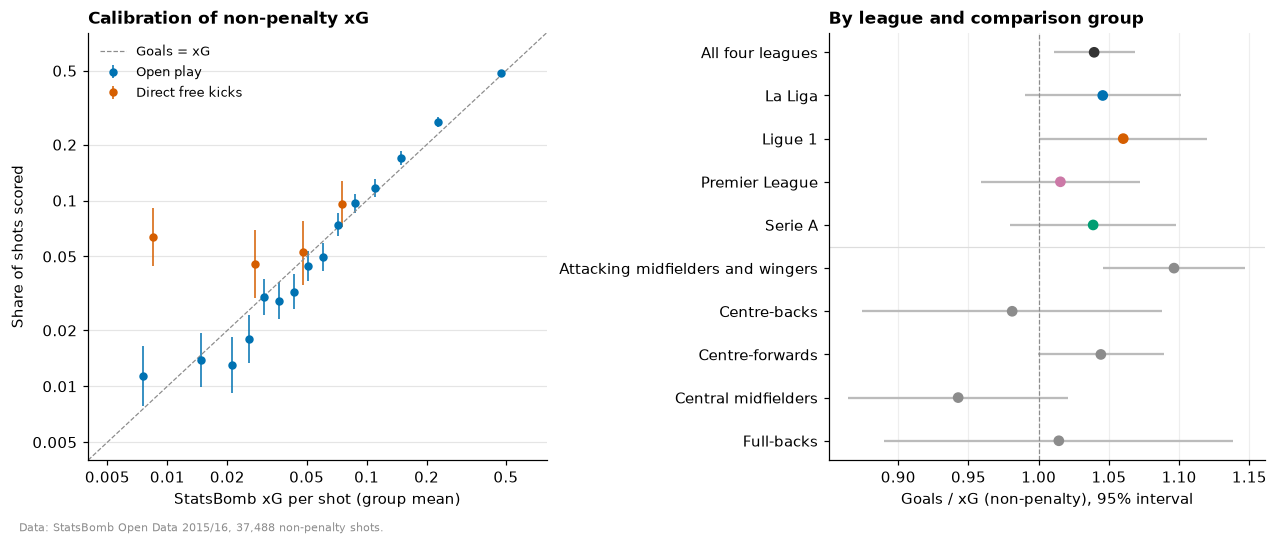

In [39]:
def wilson(goals: pd.Series, n: pd.Series, z: float = 1.96) -> tuple[pd.Series, pd.Series]:
    p = goals / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(11.5, 4.6), width_ratios=[1.05, 1], layout="constrained"
)
free_kicks = np_shots[np_shots.shot_type == "Free Kick"]
for label, d, bins, colour in [
    ("Open play", open_play, 15, OKABE_ITO[0]),
    ("Direct free kicks", free_kicks, 4, OKABE_ITO[5]),
]:
    b = d.groupby(pd.qcut(d.xg, bins), observed=True).agg(
        xg=("xg", "mean"), goals=("goal", "sum"), n=("goal", "size")
    )
    rate = b.goals / b.n
    lo, hi = wilson(b.goals, b.n)
    ax1.errorbar(b.xg, rate, yerr=[rate - lo.clip(lower=1e-3), hi - rate], fmt="o", ms=4.5,
                 lw=1, color=colour, label=label)  # fmt: skip
ax1.plot([0.004, 0.8], [0.004, 0.8], color=GREY, lw=0.8, ls="--", label="Goals = xG")
ax1.set(xscale="log", yscale="log", xlim=(0.004, 0.8), ylim=(0.004, 0.8))
for axis in (ax1.xaxis, ax1.yaxis):
    axis.set_major_locator(FixedLocator([0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5]))
    axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    axis.set_minor_locator(NullLocator())
ax1.set_xlabel("StatsBomb xG per shot (group mean)")
ax1.set_ylabel("Share of shots scored")
ax1.set_title("Calibration of non-penalty xG", fontsize=11)
ax1.legend(loc="upper left", fontsize=8.5)

rows = pd.concat(
    [
        splits["Non-penalty, by league"].assign(kind="league"),
        splits["Non-penalty, by comparison group"].assign(kind="group"),
    ]
).iloc[::-1]
half = 1.96 * np.sqrt(rows["var"]) / rows.xG
positions = np.arange(len(rows))
colours = [
    LEAGUE_COLORS.get(name, "#333333") if kind == "league" else GREY
    for name, kind in zip(rows.index, rows.kind, strict=True)
]
ax2.errorbar(rows["goals / xG"], positions, xerr=half, fmt="none", ecolor="#BBBBBB", lw=1.5)
ax2.scatter(rows["goals / xG"], positions, c=colours, s=36, zorder=3)
ax2.axvline(1, color=GREY, lw=0.8, ls="--")
ax2.axhline(len(splits["Non-penalty, by comparison group"]) - 0.5, color="#DDDDDD", lw=0.8)
ax2.set_yticks(positions, rows.index)
ax2.grid(axis="y", visible=False)
ax2.grid(axis="x", color="#EEEEEE")
ax2.set_xlabel("Goals / xG (non-penalty), 95% interval")
ax2.set_title("By league and comparison group", fontsize=11)
credit(fig, f"Data: StatsBomb Open Data 2015/16, {len(np_shots):,} non-penalty shots.")
plt.show()

xG errs in places (table and figure above). Do those errors change who ranks where? Recalibrate
xG on these shots (an isotonic fit of goals on xG, separately for open play and direct free
kicks, so every shot gets the scoring rate of shots with a similar xG), then compare each
regular's non-penalty xG per 90 before and after, within comparison group.

In [40]:
recalibrated = np_shots.xg.copy()
for _, d in np_shots.groupby("shot_type"):
    if len(d) >= 100:  # the 7 shots straight from a corner keep their xG
        iso = IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip").fit(d.xg, d.goal)
        recalibrated[d.index] = iso.predict(d.xg)

regulars = players[(players.minutes >= 900) & (players.comparison_group != "GK")].set_index(
    "player_id"
)
xg90 = (
    np_shots.assign(recalibrated=recalibrated)
    .groupby("player_id")[["xg", "recalibrated"]]
    .sum()
    .reindex(regulars.index, fill_value=0)
    .div(regulars.minutes, axis=0)
    .mul(90)
)
regular_group = regulars.comparison_group.astype(str)
pd.DataFrame(
    {
        "players": regular_group.value_counts(),
        "Spearman, xG per 90 vs recalibrated": xg90.groupby(regular_group).apply(
            lambda d: spearmanr(d.xg, d.recalibrated)[0]
        ),
        "top 20 in both": xg90.groupby(regular_group).apply(
            lambda d: len(set(d.xg.nlargest(20).index) & set(d.recalibrated.nlargest(20).index))
        ),
    }
).rename(index=COMPARISON_NAMES).round(3)

,players,"Spearman, xG per 90 vs recalibrated",top 20 in both
comparison_group,,,
Attacking midfielders and wingers,280,0.996,19
Centre-backs,261,0.996,17
Centre-forwards,165,0.998,18
Central midfielders,307,0.996,19
Full-backs,253,0.995,19


### 5.3 Is finishing a skill one season can show?

**Finishing** is non-penalty goals minus xG per shot: positive for a player who scores more than
the chances were worth. For comparison, **xG per shot** measures shot selection: how good the
chances a player shoots from are. Same split-half test as section 2, except that each half is
built to hold at least M shots (not minutes), so K is in shots. Players: outfield players with
40 non-penalty shots or more, rates centred within comparison group and league.

In [41]:
SHOT_METRICS = ["finishing", "xg_per_shot"]
SHOT_TARGETS = [5, 10, 15, 20]

season_shots = counts.groupby("player_id").shots.sum()
shooters = players[players.comparison_group != "GK"].set_index("player_id")
shooters = shooters[season_shots.reindex(shooters.index).ge(40)]
shot_curve = split_half_reliability(
    counts[counts.player_id.isin(shooters.index)],
    shooters.comparison_group.astype(str) + " | " + shooters.league,
    SHOT_METRICS,
    SHOT_TARGETS,
    draws=50,
    budget="shots",
)
K_SHOTS = stabilisation_minutes(shot_curve, SHOT_METRICS, budget="shots")
shot_reliability = shot_curve.groupby("target")[SHOT_METRICS].mean().T
shot_reliability.columns = [f"r at {t} shots" for t in SHOT_TARGETS]
shot_reliability["K: shots for r = 0.5"] = K_SHOTS
shot_reliability["shots for r = 0.7"] = minutes_for(0.7, K_SHOTS)
median_shots = season_shots.reindex(regulars.index, fill_value=0).groupby(regular_group).median()
print(
    f"{len(shooters)} players. Median non-penalty shots in the season, regulars (900+ minutes): "
    + ", ".join(f"{COMPARISON_NAMES[g]} {n:.0f}" for g, n in median_shots.items())
    + "."
)
shot_reliability.rename(index=LABELS).round(
    {
        **{c: 2 for c in shot_reliability.columns[:4]},
        "K: shots for r = 0.5": 0,
        "shots for r = 0.7": 0,
    }
)

284 players. Median non-penalty shots in the season, regulars (900+ minutes): Attacking midfielders and wingers 37, Centre-backs 9, Centre-forwards 52, Central midfielders 20, Full-backs 9.


,r at 5 shots,r at 10 shots,r at 15 shots,r at 20 shots,K: shots for r = 0.5,shots for r = 0.7
Finishing: non-penalty goals minus xG per shot,-0.00,0.01,0.01,0.02,1614.0,3765.0
Non-penalty xG per shot,0.17,0.29,0.37,0.42,28.0,66.0


### 5.4 Do players who shoot more take worse shots?

A player's non-penalty xG per 90 is **volume** (shots per 90) times **quality** (xG per shot).
The common view is that the two trade off: players who shoot a lot shoot from anywhere. For
every regular (900+ minutes), both are shrunk towards the comparison group's average, volume
with section 2's K for shots (minutes) and quality with K from 5.3 (shots), so players with few
shots are not placed at the extremes by chance. Dotted curves: equal xG per 90.

In [42]:
sums = counts.groupby("player_id")[SUMMED].sum().reindex(regulars.index)


def shrink(own: pd.Series, amount: pd.Series, k: float, group_mean: pd.Series) -> pd.Series:
    weight = amount / (amount + k)
    return weight * own.fillna(0) + (1 - weight) * regular_group.map(group_mean)


group_sums = sums.groupby(regular_group)[["shots", "xg", "minutes"]].sum()
volume = shrink(
    sums.shots / sums.minutes * 90,
    sums.minutes,
    K["shots"],
    group_sums.shots / group_sums.minutes * 90,
)
quality = shrink(
    sums.xg / sums.shots.replace(0, np.nan), sums.shots, K_SHOTS["xg_per_shot"],
    group_sums.xg / group_sums.shots,
)  # fmt: skip
many_shots = sums.shots >= 30
volume_quality = pd.DataFrame(
    {
        "players": regular_group.value_counts(),
        "Spearman, volume vs quality": pd.Series(
            {
                g: spearmanr(volume[i], quality[i])[0]
                for g, i in regular_group.groupby(regular_group).groups.items()
            }
        ),
        "players with 30+ shots": regular_group[many_shots].value_counts(),
        "Spearman, 30+ shots (unshrunk)": pd.Series(
            {
                g: spearmanr(sums.shots[i] / sums.minutes[i], sums.xg[i] / sums.shots[i])[0]
                for g, i in regular_group[many_shots].groupby(regular_group).groups.items()
                if len(i) >= 20
            }
        ),
    }
)
volume_quality.rename(index=COMPARISON_NAMES).round(2)

,players,"Spearman, volume vs quality",players with 30+ shots,"Spearman, 30+ shots (unshrunk)"
Attacking midfielders and wingers,280,-0.12,183,-0.04
Centre-backs,261,-0.13,3,NaN
Centre-forwards,165,-0.14,134,-0.15
Central midfielders,307,0.04,91,0.08
Full-backs,253,-0.04,16,NaN


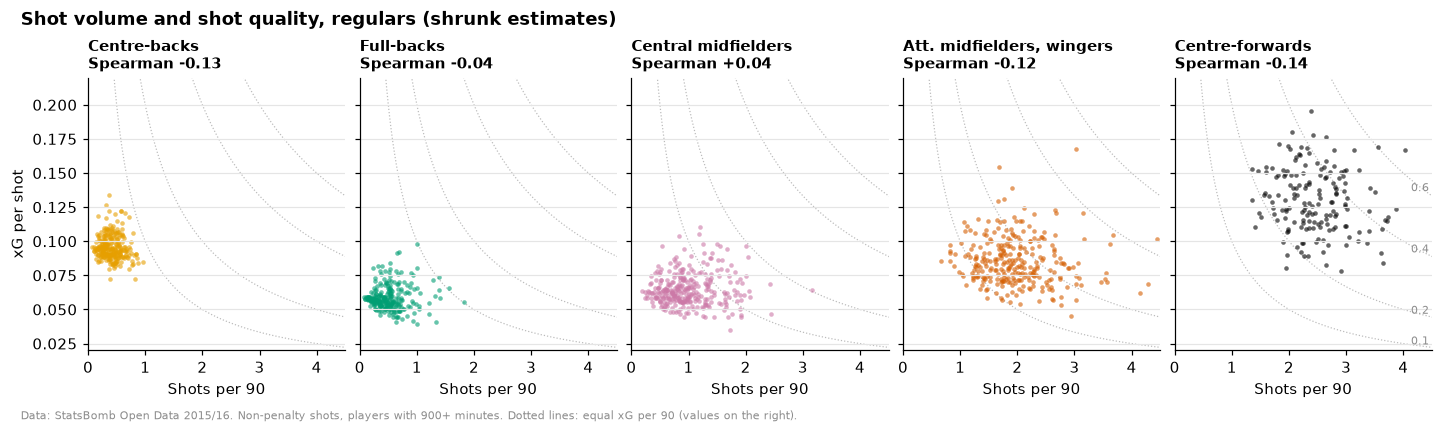

In [43]:
ORDER = ["CB", "FB", "CM", "AMW", "CF"]
SHORT = COMPARISON_NAMES | {"AMW": "Att. midfielders, wingers"}
GROUP_COLORS = {"CB": COLORS["CB"], "FB": COLORS["FB"], "CM": COLORS["CM"], "AMW": COLORS["W"],
                "CF": COLORS["CF"]}  # fmt: skip
fig, axes = plt.subplots(1, 5, figsize=(13, 3.6), sharex=True, sharey=True, layout="constrained")
grid = np.linspace(0.1, 5, 200)
for ax, g in zip(axes, ORDER, strict=True):
    i = regular_group.index[regular_group == g]
    for level in (0.1, 0.2, 0.4, 0.6):
        ax.plot(grid, level / grid, color="#BBBBBB", lw=0.8, ls=":", zorder=0)
        if g == "CF":
            ax.text(
                4.45, level / 4.45, f"{level:g}", fontsize=7, color=GREY, ha="right", va="bottom"
            )
    ax.scatter(volume[i], quality[i], s=9, alpha=0.6, color=GROUP_COLORS[g], lw=0)
    rho = volume_quality.loc[g, "Spearman, volume vs quality"]
    ax.set_title(f"{SHORT[g]}\nSpearman {rho:+.2f}", fontsize=9.5)
    ax.set_xlabel("Shots per 90")
ax = axes[0]
ax.set(xlim=(0, 4.5), ylim=(0.02, 0.22))
ax.set_ylabel("xG per shot")
fig.suptitle(
    "Shot volume and shot quality, regulars (shrunk estimates)",
    x=0.01, ha="left", fontweight="bold", fontsize=12,
)  # fmt: skip
credit(
    fig,
    "Data: StatsBomb Open Data 2015/16. Non-penalty shots, players with 900+ minutes. "
    "Dotted lines: equal xG per 90 (values on the right).",
)
plt.show()

### What section 5 shows

- **The shot data is complete.** All 37,888 shots carry an xG and every non-penalty shot has a
  freeze frame. Penalties all get the same xG (0.7835); the 7 shots straight from a corner sit
  at the xG floor (3 went in). The 53 shots of the two matches without fidelity metadata differ
  from the rest (0.069 xG per shot against 0.099, 47% in the box against 58%) by about 1.6
  standard errors, within chance for so few shots. Goals reconcile with the scores: 3,869 from
  shots plus 128 own goals.
- **xG is slightly low, the same in every league.** Non-penalty shots produced 3,569 goals
  against 3,433 xG (+4%, about 2.7 standard deviations). Every league sits between +2% and +6%,
  none apart from the others beyond chance, and the Premier League's recording change did not
  touch shots.
- **The errors are in the kind of chance.** Direct free kicks went in 1.6 times as often as
  their xG says (113 goals from 69.5 xG). In open play, shots with xG under 0.06 score 15-18%
  less than predicted and chances of 0.1 to 0.4 score 10-13% more. Attacking midfielders and
  wingers score 10% above their xG as a group.
- **Those errors barely move rankings.** Recalibrating xG on these shots changes each group's
  order of non-penalty xG per 90 very little (Spearman ≥ 0.995; 17 to 19 of the top 20 stay).
- **Finishing is not visible in one season.** Split-half reliability of goals minus xG per shot
  stays at 0.02 or below up to 20 shots per half (K about 1,600 shots), while a regular
  centre-forward takes a median of 52 non-penalty shots a season. **Shot selection is a stable
  trait:** xG per shot reaches r = 0.5 at about 28 shots.
- **Volume and quality hardly trade off.** Within each group, shots per 90 and xG per shot are
  close to independent (Spearman −0.14 to +0.04). Centre-forwards, attacking midfielders and
  wingers, and centre-backs who shoot more take slightly worse shots; central midfielders and
  full-backs show no relationship. Among players with 30+ shots, whose xG per shot is more
  reliable, the picture is the same (−0.15 to +0.08). Two players with the same xG per 90 can
  get there in different ways.

**Decision: how xG is used.**
- **StatsBomb's non-penalty xG, as published, measures attacking output**: no league
  adjustment and no recalibration. The leagues differ by no more than chance, and recalibrating
  barely changes rankings.
- **Finishing does not rank players**, like goals: one season cannot tell a good finisher from a
  lucky one.
- **Profiles show shot volume and shot quality next to xG per 90**: non-penalty shots per 90 and
  xG per shot, each shrunk towards the comparison group's average with its own K (for xG per
  shot, about 28 shots).

## 6. Do the event locations mean what they say?

Phase 3 leans on where things happen: passes into the box, progressive passes and carries, how
high a player defends, which zones a player covers. Those numbers are only as good as the
coordinates. StatsBomb's pitch is 120 × 80 yards and, by the data dictionary, every event is
described from the acting team's side, attacking towards x = 120. This section checks the
coordinates' limits and precision, the direction of play, where each position acts, and whether
location-based numbers are on one scale across the leagues.

### 6.1 Limits and precision

Event locations by league, with the two matches without fidelity metadata apart.

In [44]:
frame = (
    con.sql("""
    SELECT CASE WHEN m.xy_fidelity_version IS NULL THEN 'No fidelity metadata (2 matches)'
                ELSE c.competition_name END AS matches,
           count(*) AS events,
           count(*) FILTER (WHERE e.x < 0 OR e.x > 120 OR e.y < 0 OR e.y > 80) AS outside,
           min(e.x) AS min_x, max(e.x) AS max_x, min(e.y) AS min_y, max(e.y) AS max_y,
           100 * avg((abs(e.x * 10 - round(e.x * 10)) < 1e-6
                      AND abs(e.y * 10 - round(e.y * 10)) < 1e-6)::INT) AS "on the 0.1 grid (%)",
           count(DISTINCT e.x) AS distinct_x, count(DISTINCT e.y) AS distinct_y
    FROM events e
    JOIN matches m ON m.match_id = e.match_id
    JOIN competitions c ON c.competition_id = m.competition_id AND c.season_id = m.season_id
    WHERE m.scouting_pool AND e.x IS NOT NULL
    GROUP BY ALL ORDER BY ALL
""")
    .df()
    .set_index("matches")
)
display(frame.round(1))

located = con.sql("""
    SELECT e.type, count(*) AS events, count(e.x) AS with_location
    FROM events e JOIN matches m ON m.match_id = e.match_id
    WHERE m.scouting_pool GROUP BY ALL ORDER BY events DESC, e.type
""").df()
never = located[located.with_location == 0].type
partly = located[located.with_location.between(1, located.events - 1)]
print("Never located (match administration):", ", ".join(never))
for r in partly.itertuples():
    print(f"  {r.type}: {r.with_location:,} of {r.events:,} located")

throw_ins = con.sql("""
    SELECT y, count(*) AS n FROM passes
    WHERE pass_type = 'Throw-in' AND match_id IN (SELECT match_id FROM matches WHERE scouting_pool)
    GROUP BY y ORDER BY n DESC
""").df()
touchline = throw_ins[throw_ins.y.isin([0.1, 80.0])].n.sum()
print(
    f"Throw-ins: {touchline:,} of {throw_ins.n.sum():,} at y = 0.1 or 80.0 "
    f"({touchline / throw_ins.n.sum():.2%})."
)
ends_outside = con.sql("""
    SELECT 'passes' AS kind, count(*) FILTER (WHERE end_x > 120 OR end_y > 80) AS n FROM passes
    WHERE match_id IN (SELECT match_id FROM matches WHERE scouting_pool)
    UNION ALL
    SELECT 'carries', count(*) FILTER (WHERE end_x > 120 OR end_y > 80) FROM carries
    WHERE match_id IN (SELECT match_id FROM matches WHERE scouting_pool)
""").df()
print(
    "End locations beyond 120 x 80:",
    ", ".join(f"{r.n} {r.kind}" for r in ends_outside.itertuples()),
)

,events,outside,min_x,max_x,min_y,max_y,on the 0.1 grid (%),distinct_x,distinct_y
matches,,,,,,,,,
La Liga,1286172,9,0.1,120.3,0.1,80.4,100.0,1203,801
Ligue 1,1345321,2,0.1,120.5,0.1,80.0,100.0,1202,800
No fidelity metadata (2 matches),7018,0,0.1,120.0,0.1,80.0,100.0,1114,768
Premier League,1305696,3,0.1,120.9,0.1,80.0,100.0,1203,800
Serie A,1339792,1,0.1,120.3,0.1,80.0,100.0,1201,800


Never located (match administration): Substitution, Half End, Half Start, Tactical Shift, Starting XI, Player Off, Player On
  Goal Keeper: 46,319 of 46,365 located
  Injury Stoppage: 3 of 5,409 located
  Bad Behaviour: 2 of 1,237 located
Throw-ins: 70,207 of 70,260 at y = 0.1 or 80.0 (99.92%).
End locations beyond 120 x 80: 16 passes, 1 carries


The coordinates are a **0.1-yard grid running from 0.1 to 120.0 along the pitch and 0.1 to
80.0 across it**: throw-ins sit on y = 0.1 or y = 80.0, the touchlines. A handful of events lie
up to 0.9 yards beyond, a rounding matter. Precision and limits are the same in every league
and in the two matches without fidelity metadata, which therefore record locations like the
rest. Only match administration (lineups, substitutions, half starts and ends, and almost all
injury stoppages and cards) has no location, along with 46 goalkeeper events.

### 6.2 Which way is the pitch?

If every event is described from the acting team's side, set pieces sit at fixed places, shots
fall in the attacking half, and left backs play at low y (y = 0 is the attacking team's left).
Events the two teams both record give a sharper test: a foul committed and the foul won, a
dribble and the player dribbled past, a duel and the action it contests, the two sides of a
50/50. They happen at one spot, so one team's (x, y) must be the other's (120.1 − x, 80.1 − y),
the mirror image on a grid that runs from 0.1 to 120.0.

In [45]:
POOL = "match_id IN (SELECT match_id FROM matches WHERE scouting_pool)"
ON_BALL_PRC = "type IN ('Pass', 'Carry', 'Ball Receipt*')"
CHECKS = {
    "Kick-offs at the centre spot (within 1 yard of 60, 40)": (
        "passes", "pass_type = 'Kick Off'", "abs(x - 60) <= 1 AND abs(y - 40) <= 1"),
    "Goal kicks in front of the team's own goal (x ≤ 7, 30 ≤ y ≤ 50)": (
        "passes", "pass_type = 'Goal Kick'", "x <= 7 AND y BETWEEN 30 AND 50"),
    "Corners at the opponent's corner flags (x ≥ 119, y ≤ 1 or y ≥ 79)": (
        "passes", "pass_type = 'Corner'", "x >= 119 AND (y <= 1 OR y >= 79)"),
    "Penalties at the opponent's penalty spot (within 1 yard of 108, 40)": (
        "shots", "shot_type = 'Penalty'", "abs(x - 108) <= 1 AND abs(y - 40) <= 1"),
    "Other shots in the attacking half (x > 60)": ("shots", "shot_type <> 'Penalty'", "x > 60"),
    "Goalkeeper actions in the team's own half (x < 60)": (
        "events", "type = 'Goal Keeper' AND x IS NOT NULL", "x < 60"),
    "Own goals for the team, at the opponent's end (x > 60)": (
        "events", "type = 'Own Goal For'", "x > 60"),
    "Own goals against the team, at its own end (x < 60)": (
        "events", "type = 'Own Goal Against'", "x < 60"),
    "Left backs' passes, carries and receptions on the left (y < 40)": (
        "events", f"position = 'Left Back' AND {ON_BALL_PRC}", "y < 40"),
    "Right backs' passes, carries and receptions on the right (y > 40)": (
        "events", f"position = 'Right Back' AND {ON_BALL_PRC}", "y > 40"),
}  # fmt: skip
rows = {}
for label, (table, which, expected) in CHECKS.items():
    rows[label] = con.sql(f"""
        SELECT count(*) AS events, 100 * avg(({expected})::INT) AS as_expected
        FROM {table} WHERE {POOL} AND {which}
    """).fetchone()

pairs = (
    con.sql(f"""
    WITH ev AS (
        SELECT event_id, team_id, type, x, y, related_events FROM events
        WHERE {POOL} AND x IS NOT NULL),
    pairs AS (
        SELECT least(a.type, b.type) AS t1, greatest(a.type, b.type) AS t2,
               a.x + b.x AS sum_x, a.y + b.y AS sum_y
        FROM (SELECT *, unnest(related_events) AS related FROM ev) a
        JOIN ev b ON b.event_id = a.related
        WHERE a.team_id <> b.team_id AND a.event_id < b.event_id)
    SELECT count(*) AS events,
           avg((abs(sum_x - 120.1) < 0.05 AND abs(sum_y - 80.1) < 0.05)::INT) AS exact,
           avg((abs(sum_x - 120.1) <= 1 AND abs(sum_y - 80.1) <= 1)::INT) AS within_1_yard
    FROM pairs
    WHERE (t1 = 'Foul Committed' AND t2 = 'Foul Won') OR (t1 = 'Dribble' AND t2 = 'Dribbled Past')
       OR (t1 = '50/50' AND t2 = '50/50')
       OR ('Duel' IN (t1, t2)
           AND (t1 IN ('Pass', 'Dispossessed', 'Dribble', 'Clearance', 'Shot', 'Miscontrol')
                OR t2 IN ('Pass', 'Dispossessed', 'Dribble', 'Clearance', 'Shot', 'Miscontrol')))
""")
    .df()
    .iloc[0]
)
rows["Same-spot events of the two teams mirrored exactly (pairs)"] = (
    int(pairs.events),
    100 * pairs.exact,
)
direction = pd.DataFrame(rows, index=["events", "as expected (%)"]).T
display(direction.astype({"events": int}).round(2))
print(f"Mirrored pairs within 1 yard: {pairs.within_1_yard:.2%}.")

,events,as expected (%)
"Kick-offs at the centre spot (within 1 yard of 60, 40)",6973,100.00
"Goal kicks in front of the team's own goal (x ≤ 7, 30 ≤ y ≤ 50)",25281,99.95
"Corners at the opponent's corner flags (x ≥ 119, y ≤ 1 or y ≥ 79)",15475,99.95
"Penalties at the opponent's penalty spot (within 1 yard of 108, 40)",400,100.00
Other shots in the attacking half (x > 60),37488,99.88
Goalkeeper actions in the team's own half (x < 60),46319,99.99
"Own goals for the team, at the opponent's end (x > 60)",128,100.00
"Own goals against the team, at its own end (x < 60)",128,100.00
"Left backs' passes, carries and receptions on the left (y < 40)",350777,98.55
"Right backs' passes, carries and receptions on the right (y > 40)",346697,98.70


Mirrored pairs within 1 yard: 99.90%.


Every check passes: set pieces sit where they should, shots and goalkeepers are at the right
ends, left backs play on the left, and the events the two teams share mirror each other exactly
(the rest are almost all within a yard). **The direction is as documented: the acting team
attacks towards x = 120 and y = 0 is its left.**

### 6.3 Does the end of the stadium matter?

The fixed set-piece spots give away which end of the stadium a team is attacking: kick-offs are
placed at x = 60 or 61 and goal kicks at x = 6 or 7, depending on the team and the half. If
that is the end, the placement must be the same for a team throughout a half, swap at
half-time, and be opposite for the two teams. Every team then plays one half towards each end,
so comparing a team's two halves of the same match isolates the end from everything else.

In [46]:
spots = con.sql(f"""
    SELECT match_id, period, team_id,
           count(*) AS spots,
           CASE WHEN bool_and((pass_type = 'Kick Off' AND x = 60)
                              OR (pass_type = 'Goal Kick' AND x = 6)) THEN 'A'
                WHEN bool_and((pass_type = 'Kick Off' AND x = 61)
                              OR (pass_type = 'Goal Kick' AND x = 7)) THEN 'B' END AS pitch_end
    FROM passes
    WHERE {POOL} AND period <= 2 AND pass_type IN ('Kick Off', 'Goal Kick')
      AND ((pass_type = 'Kick Off' AND x IN (60, 61)) OR (pass_type = 'Goal Kick' AND x IN (6, 7)))
    GROUP BY ALL
""").df()
halves = con.sql(f"""
    SELECT DISTINCT match_id, period, team_id FROM events
    WHERE {POOL} AND period <= 2 AND type = 'Half Start'
""").df()
ends = halves.merge(spots, how="left")
mixed = ends.pitch_end.isna() & ends.spots.notna()
other_team = ends.merge(ends, on=["match_id", "period"], suffixes=("", "_opp")).query(
    "team_id != team_id_opp"
)
other_half = ends.merge(ends, on=["match_id", "team_id"], suffixes=("", "_2")).query(
    "period == 1 and period_2 == 2"
)
both = other_team.pitch_end.notna() & other_team.pitch_end_opp.notna()
both_halves = other_half.pitch_end.notna() & other_half.pitch_end_2.notna()
print(
    f"{len(ends):,} team-halves: {ends.pitch_end.notna().sum():,} with fixed spots, "
    f"{mixed.sum()} mixing both placements."
)
print(
    f"Opposite to the other team in the same half: "
    f"{(other_team.pitch_end != other_team.pitch_end_opp)[both].mean():.1%} "
    f"of {both.sum():,}; swapped at half-time: "
    f"{(other_half.pitch_end != other_half.pitch_end_2)[both_halves].mean():.1%} "
    f"of {both_halves.sum():,}."
)
# A team-half without a set-piece spot takes the opposite of its opponent's.
fill = other_team.set_index(["match_id", "period", "team_id"]).pitch_end_opp.map(
    {"A": "B", "B": "A"}
)
ends = ends.set_index(["match_id", "period", "team_id"])
ends["pitch_end"] = ends.pitch_end.fillna(fill)
print(f"End known for {ends.pitch_end.notna().mean():.1%} of team-halves.")

6,068 team-halves: 6,023 with fixed spots, 0 mixing both placements.
Opposite to the other team in the same half: 100.0% of 5,978; swapped at half-time: 100.0% of 2,989.
End known for 100.0% of team-halves.


In [47]:
con.register("team_half_ends", ends.reset_index()[["match_id", "period", "team_id", "pitch_end"]])
by_end = con.sql(f"""
    SELECT match_id, team_id, pitch_end,
           avg(x) FILTER (WHERE {ON_BALL_PRC}) AS on_ball_x,
           avg(y) FILTER (WHERE {ON_BALL_PRC}) AS on_ball_y,
           100 * avg((x >= 80)::INT) FILTER (WHERE {ON_BALL_PRC}) AS on_ball_final_third,
           100 * avg({in_box("x", "y")}::INT) FILTER (WHERE {ON_BALL_PRC}) AS on_ball_box,
           avg(y) FILTER (WHERE type = 'Pressure') AS pressure_y,
           avg(y) FILTER (WHERE type = 'Duel') AS duel_y,
           avg(y) FILTER (WHERE type = 'Interception') AS interception_y
    FROM events JOIN team_half_ends USING (match_id, period, team_id)
    WHERE x IS NOT NULL
    GROUP BY ALL
""").df()
END_METRICS = {
    "on_ball_x": "Passes, carries, receptions: mean x (along)",
    "on_ball_y": "Passes, carries, receptions: mean y (across)",
    "on_ball_final_third": "Passes, carries, receptions: % in the final third",
    "on_ball_box": "Passes, carries, receptions: % in the box",
    "pressure_y": "Pressures: mean y",
    "duel_y": "Duels: mean y",
    "interception_y": "Interceptions: mean y",
}
wide = by_end.pivot_table(
    index=["match_id", "team_id"], columns="pitch_end", values=list(END_METRICS)
)
diff = {m: wide[m]["B"] - wide[m]["A"] for m in END_METRICS}
end_table = pd.DataFrame(
    {
        "End A": [wide[m]["A"].mean() for m in END_METRICS],
        "End B": [wide[m]["B"].mean() for m in END_METRICS],
        "B - A": [diff[m].mean() for m in END_METRICS],
        "standard error": [diff[m].std() / np.sqrt(diff[m].count()) for m in END_METRICS],
    },
    index=END_METRICS.values(),
)
display(end_table.round(2))

,End A,End B,B - A,standard error
"Passes, carries, receptions: mean x (along)",60.67,61.25,0.57,0.10
"Passes, carries, receptions: mean y (across)",38.53,41.03,2.50,0.09
"Passes, carries, receptions: % in the final third",25.38,26.15,0.77,0.15
"Passes, carries, receptions: % in the box",3.16,3.27,0.11,0.03
Pressures: mean y,39.77,41.28,1.51,0.12
Duels: mean y,40.46,40.22,-0.25,0.17
Interceptions: mean y,39.56,39.91,0.34,0.31


The placement never mixes within a team-half, is always opposite to the opponent's and always
swaps at half-time, so it marks the end of the stadium a team attacks (called A and B here).
**The end leaves a small mark.** In its half towards end B, a team's passes, carries and
receptions sit about half a yard further forward and **two and a half yards further to the
right** than in its half towards end A, with about 3% more of them in the final third and in
the box; pressures shift 1.5 yards. In the stadium's own frame, both teams' actions lean
towards the same touchline, so the shift belongs to the ground, not to the team. Duels and
interceptions do not move beyond chance. The data cannot say whether this comes from how
locations are captured or from how play spreads in the stadium.

It cannot favour a player over a season, because each player's matches split between the
two ends:

In [48]:
side_share = (
    con.sql(f"""
    SELECT player_id, avg((pitch_end = 'B')::INT) AS share_end_b, count(*) AS actions
    FROM events JOIN team_half_ends USING (match_id, period, team_id)
    WHERE {ON_BALL_PRC}
    GROUP BY ALL
""")
    .df()
    .set_index("player_id")
)
regular_ids = players.loc[players.minutes >= 900, "player_id"]
share = side_share.share_end_b.reindex(regular_ids).dropna()
lo, mid, hi = share.quantile([0.05, 0.5, 0.95])
box_gap = end_table.loc[END_METRICS["on_ball_box"], ["End A", "End B"]]
gap = box_gap["End B"] / box_gap["End A"] - 1
print(
    f"Regulars' passes, carries and receptions towards end B: median {mid:.1%}, "
    f"90% of players between {lo:.1%} and {hi:.1%}."
)
print(
    f"With box shares {gap:+.1%} towards end B, a player at the 5th or 95th percentile "
    f"is moved by about {max(mid - lo, hi - mid) * gap:.1%} in the box."
)

Regulars' passes, carries and receptions towards end B: median 50.1%, 90% of players between 43.9% and 56.4%.
With box shares +3.5% towards end B, a player at the 5th or 95th percentile is moved by about 0.2% in the box.


### 6.4 Where each position acts

On-ball actions (touches, as defined in section 2) and defensive actions (tackles,
interceptions, ball recoveries, clearances, blocks) of players with 900+ minutes, each placed in
the position group the player held at the time of the event. Shading: the group's actions per
2 × 2-yard cell, lightly smoothed, each pitch on its own scale; teams attack upwards.

Actions without a position group: 0


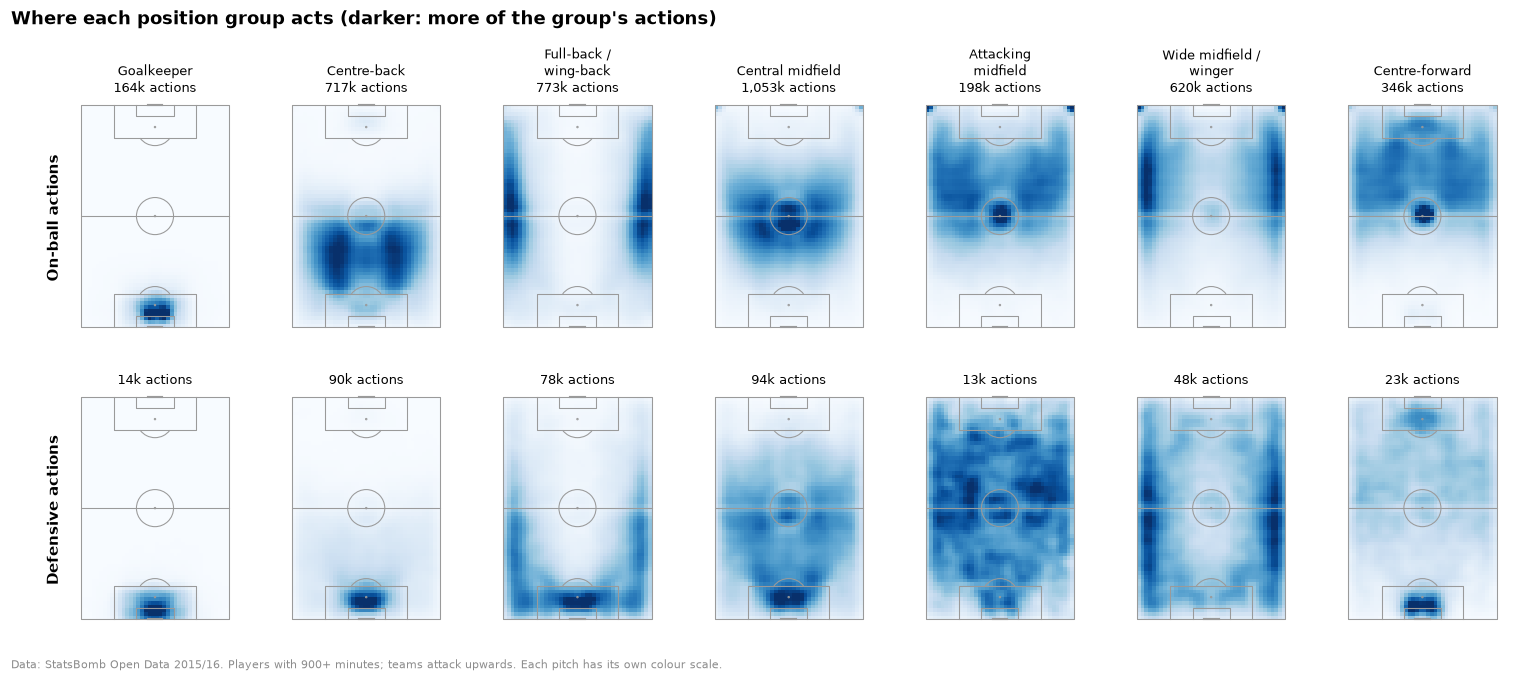

In [49]:
on_ball_types = ", ".join(f"'{t}'" for t in ON_BALL)
con.register("regular_players", pd.DataFrame({"player_id": regular_ids}))
grid_counts = con.sql(f"""
    WITH acts AS (
        SELECT 'On-ball actions' AS kind, position_id, x, y FROM events
        WHERE {POOL} AND type IN ({on_ball_types})
          AND event_id NOT IN (SELECT event_id FROM ball_receipts WHERE outcome = 'Incomplete')
          AND event_id NOT IN (SELECT event_id FROM ball_recoveries WHERE recovery_failure)
          AND player_id IN (SELECT player_id FROM regular_players)
        UNION ALL
        SELECT 'Defensive actions', position_id, x, y FROM defensive_actions
        WHERE {POOL}
          AND action IN ('Tackle', 'Interception', 'Ball Recovery', 'Clearance', 'Block')
          AND player_id IN (SELECT player_id FROM regular_players))
    SELECT kind, position_id,
           least(floor(x / 2), 59) * 2 + 1 AS cx, least(floor(y / 2), 39) * 2 + 1 AS cy,
           count(*) AS n, sum(x) AS sum_x, sum(abs(y - 40)) AS sum_width,
           count(*) FILTER (WHERE x >= 80) AS final_third,
           count(*) FILTER (WHERE {in_box("x", "y")}) AS box,
           count(*) FILTER (WHERE x <= 18 AND y BETWEEN 18 AND 62) AS own_box
    FROM acts WHERE x IS NOT NULL GROUP BY ALL
""").df()
POSITION_GROUP = {pid: g.code for g in cfg.position_groups for pid in g.position_ids}
grid_counts["group"] = grid_counts.position_id.map(POSITION_GROUP)
print(f"Actions without a position group: {grid_counts.loc[grid_counts.group.isna(), 'n'].sum():,}")
grid_counts = grid_counts.dropna(subset=["group"])
KINDS = ["On-ball actions", "Defensive actions"]
pitch = VerticalPitch(
    pitch_type="statsbomb", line_color="#9A9A9A", linewidth=0.7, line_zorder=2, pad_top=2
)
fig, axes = plt.subplots(2, len(GROUPS), figsize=(14, 5.9))
for row, kind in enumerate(KINDS):
    for ax, g in zip(axes[row], GROUPS, strict=True):
        d = grid_counts[(grid_counts.kind == kind) & (grid_counts.group == g)]
        stat = pitch.bin_statistic(d.cx, d.cy, values=d.n, statistic="sum", bins=(60, 40))
        stat["statistic"] = gaussian_filter(stat["statistic"], 1.2)
        pitch.draw(ax=ax)
        pitch.heatmap(
            stat, ax=ax, cmap="Blues", vmin=0, vmax=np.quantile(stat["statistic"], 0.995),
            edgecolors="none",
        )  # fmt: skip
        title = f"{textwrap.fill(GROUP_NAMES[g], 16)}\n" if row == 0 else ""
        ax.set_title(f"{title}{d.n.sum() / 1000:,.0f}k actions", fontsize=8.5, loc="center",
                     fontweight="normal")  # fmt: skip
    axes[row, 0].text(
        -0.12, 0.5, kind, transform=axes[row, 0].transAxes, rotation=90, va="center",
        ha="center", fontsize=10, fontweight="bold",
    )  # fmt: skip
fig.suptitle(
    "Where each position group acts (darker: more of the group's actions)",
    x=0.01, ha="left", fontweight="bold", fontsize=12,
)  # fmt: skip
fig.subplots_adjust(left=0.04, right=0.99, top=0.84, bottom=0.03, hspace=0.25, wspace=0.08)
credit(
    fig,
    "Data: StatsBomb Open Data 2015/16. Players with 900+ minutes; teams attack upwards. "
    "Each pitch has its own colour scale.",
)
plt.show()

In [50]:
SUMMED_GRID = ["n", "sum_x", "sum_width", "final_third", "box", "own_box"]
summary = grid_counts.groupby(["group", "kind"])[SUMMED_GRID].sum()
where = pd.DataFrame(
    {
        "mean x": summary.sum_x / summary.n,
        "distance from centre line": summary.sum_width / summary.n,
        "final third (%)": summary.final_third / summary.n * 100,
        "box (%)": summary.box / summary.n * 100,
        "own box (%)": summary.own_box / summary.n * 100,
    }
).unstack("kind")
where = where.reindex(GROUPS).swaplevel(axis=1)[KINDS]
where.index = [GROUP_NAMES[g] for g in where.index]
set_piece = con.sql(f"""
    SELECT avg((play_pattern IN ('From Corner', 'From Free Kick'))::INT) FROM defensive_actions
    WHERE {POOL} AND x <= 18 AND y BETWEEN 18 AND 62
      AND action IN ('Tackle', 'Interception', 'Ball Recovery', 'Clearance', 'Block')
      AND position_id IN ({", ".join(str(p) for p, g in POSITION_GROUP.items() if g == "CF")})
      AND player_id IN (SELECT player_id FROM regular_players)
""").fetchone()[0]
display(where.round(1))
print(
    "Centre-forwards' defensive actions in their own box that follow a corner or free kick: "
    f"{set_piece:.0%}."
)

kind                   On-ball actions                            \
                                mean x distance from centre line   
Goalkeeper                        11.1                       7.1   
Centre-back                       40.7                      16.8   
Full-back / wing-back             60.6                      29.5   
Central midfield                  60.3                      17.3   
Attacking midfield                73.2                      19.7   
Wide midfield / winger            74.6                      24.5   
Centre-forward                    78.7                      18.6   

kind                                                       Defensive actions  \
                       final third (%) box (%) own box (%)            mean x   
Goalkeeper                         0.0     0.0        86.6               8.6   
Centre-back                        3.0     1.2         7.4              28.2   
Full-back / wing-back             26.0     1.5         3.1              38.1   
Central midfield                  18.5     1.5         1.8              48.6   
Attacking midfield                39.9     4.4         0.6              61.2   
Wide midfield / winger            45.1     5.2         0.8              57.2   
Centre-forward                    49.8    10.5         0.9              65.8   

kind                                                                      \
                       distance from centre line final third (%) box (%)   
Goalkeeper                                   8.2             0.0     0.0   
Centre-back                                 14.9             2.1     0.8   
Full-back / wing-back                       23.3            11.3     1.1   
Central midfield                            17.4            14.4     1.5   
Attacking midfield                          19.0            30.4     5.0   
Wide midfield / winger                      23.1            28.1     5.0   
Centre-forward                              17.5            38.8    11.2   

kind                                
                       own box (%)  
Goalkeeper                    92.7  
Centre-back                   34.8  
Full-back / wing-back         20.0  
Central midfield              12.1  
Attacking midfield             6.2  
Wide midfield / winger         6.9  
Centre-forward                11.4

Centre-forwards' defensive actions in their own box that follow a corner or free kick: 93%.


Each group acts where its position says. Goalkeepers act almost only in their own box (87% of
their on-ball actions); centre-backs play deep and central (mean x 41); full-backs and wingers
are the widest groups (29 and 24 yards from the centre line on average); central midfielders
hold the middle; centre-forwards are the most advanced (mean x 79, 10% of their on-ball actions
in the opponent's box). Fixed spots show up too: the kick-off spot for midfielders and
forwards, the corner flags for attacking midfielders and wingers. Every group's defensive
actions sit deeper than its on-ball actions, and 11% of centre-forwards' defensive actions are
in their own box, almost all (93%) after a corner or a free kick.

### 6.5 Are location-based numbers on one scale across the leagues?

Section 3 compared counts. Here are numbers defined by location, in simple versions of the usual
definitions (open play, completed passes):
- **into the final third / into the box**: passes or carries that start outside the zone and end
  in it (final third: x ≥ 80; box as in section 2);
- **progressive passes**: move the ball at least 10 yards towards the opponent's goal line,
  starting outside the defending 40% of the pitch (x ≥ 48);
- **progressive carries**: at least 10 yards towards the goal line, ending in the opponent's
  half;
- **passes received in the box**: completed ball receipts in the box;
- **height of defensive actions**: mean x of tackles, interceptions, recoveries, clearances and
  blocks.

The same tests as section 3: per team and 90 real minutes, the share of the variation explained
by the league (η²); for outfield players with 900+ minutes, the league's share once the
comparison group is accounted for (partial η²) and each league's gap within group; and the
change in each league from match weeks 1–18 to 19–38, where the Premier League's recording
changed.

In [51]:
SPATIAL = {
    "passes_into_final_third": "Completed passes into the final third",
    "passes_into_box": "Completed passes into the box",
    "progressive_passes": "Progressive passes",
    "carries_into_final_third": "Carries into the final third",
    "carries_into_box": "Carries into the box",
    "progressive_carries": "Progressive carries",
    "receipts_in_box": "Passes received in the box",
    "defence_height": "Height of defensive actions (x)",
}
IN_BOX, END_IN_BOX = in_box("x", "y"), in_box("end_x", "end_y")
spatial_counts = con.sql(f"""
    WITH
    p AS (
        SELECT match_id, player_id,
               count(*) FILTER (WHERE x < 80 AND end_x >= 80) AS passes_into_final_third,
               count(*) FILTER (WHERE {END_IN_BOX} AND NOT {IN_BOX})
                   AS passes_into_box,
               count(*) FILTER (WHERE x >= 48 AND end_x - x >= 10) AS progressive_passes
        FROM passes WHERE {POOL} AND {OPEN_PLAY} AND completed GROUP BY ALL),
    c AS (
        SELECT match_id, player_id,
               count(*) FILTER (WHERE x < 80 AND end_x >= 80) AS carries_into_final_third,
               count(*) FILTER (WHERE {END_IN_BOX} AND NOT {IN_BOX})
                   AS carries_into_box,
               count(*) FILTER (WHERE end_x >= 60 AND end_x - x >= 10) AS progressive_carries
        FROM carries WHERE {POOL} GROUP BY ALL),
    r AS (
        SELECT match_id, player_id, count(*) FILTER (WHERE {IN_BOX}) AS receipts_in_box
        FROM ball_receipts WHERE {POOL} AND outcome IS NULL GROUP BY ALL),
    d AS (
        SELECT match_id, player_id, count(*) AS defensive_actions, sum(x) AS sum_defence_x
        FROM defensive_actions
        WHERE {POOL}
          AND action IN ('Tackle', 'Interception', 'Ball Recovery', 'Clearance', 'Block')
        GROUP BY ALL)
    SELECT pm.match_id, m.match_week, pm.team_id, pm.player_id, pm.seconds_played / 60 AS minutes,
           p.* EXCLUDE (match_id, player_id), c.* EXCLUDE (match_id, player_id),
           r.* EXCLUDE (match_id, player_id), d.* EXCLUDE (match_id, player_id)
    FROM player_matches pm
    JOIN matches m USING (match_id)
    LEFT JOIN p USING (match_id, player_id) LEFT JOIN c USING (match_id, player_id)
    LEFT JOIN r USING (match_id, player_id) LEFT JOIN d USING (match_id, player_id)
    WHERE m.scouting_pool AND pm.played
""").df()
SPATIAL_COUNTS = spatial_counts.columns[5:]
spatial_counts[SPATIAL_COUNTS] = spatial_counts[SPATIAL_COUNTS].fillna(0).astype(float)
PER_90_SPATIAL = [m for m in SPATIAL if m != "defence_height"]


def spatial_rates(sums: pd.DataFrame, minutes: pd.Series) -> pd.DataFrame:
    out = sums[PER_90_SPATIAL].div(minutes, axis=0) * 90
    out["defence_height"] = sums.sum_defence_x / sums.defensive_actions.replace(0, np.nan)
    return out


team_sp = (
    spatial_counts.groupby(["match_id", "match_week", "team_id"])[SPATIAL_COUNTS].sum()
    .reset_index()
    .merge(team[["match_id", "team_id", "league", "match_minutes"]], on=["match_id", "team_id"])
)  # fmt: skip
team_sp = team_sp.join(spatial_rates(team_sp, team_sp.match_minutes).add_prefix("rate_"))

sums_sp = spatial_counts.groupby("player_id")[[*SPATIAL_COUNTS, "minutes"]].sum()
out_ids = regular_out.player_id
player_sp = spatial_rates(sums_sp.loc[out_ids], sums_sp.loc[out_ids, "minutes"]).assign(
    league=regular_out.league.to_numpy(), group=regular_out.comparison_group.astype(str).to_numpy()
)
spatial_effects = pd.DataFrame(
    {
        SPATIAL[m]: {
            "teams η²": eta_squared(team_sp[f"rate_{m}"], team_sp.league),
            **league_effect(player_sp, m),
        }
        for m in SPATIAL
    }
).T
spatial_effects.round({"teams η²": 3, "partial η²": 3, **dict.fromkeys(LEAGUES, 1)})

,teams η²,partial η²,La Liga,Ligue 1,Premier League,Serie A
Completed passes into the final third,0.003,0.003,-0.8,-1.9,4.4,-1.5
Completed passes into the box,0.017,0.010,0.8,-9.8,1.6,7.3
Progressive passes,0.001,0.000,1.1,-0.7,0.6,-1.0
Carries into the final third,0.004,0.014,-5.9,-2.3,-1.9,9.9
Carries into the box,0.019,0.008,-2.6,-10.7,6.8,6.7
Progressive carries,0.003,0.015,-6.9,0.7,-3.2,9.1
Passes received in the box,0.019,0.010,2.0,-7.1,5.8,-0.5
Height of defensive actions (x),0.002,0.017,-0.8,1.0,-1.9,1.6


League gaps within comparison group above are in % of the average group mean. The change from
the first to the second half of the season, per team and match:

In [52]:
halves_sp = (
    team_sp.assign(weeks=np.where(team_sp.match_week <= 18, "1–18", "19–38"))
    .groupby(["league", "weeks"])[[f"rate_{m}" for m in SPATIAL]]
    .mean()
)
season_change = (halves_sp.xs("19–38", level="weeks") / halves_sp.xs("1–18", level="weeks")).T
season_change.index = SPATIAL.values()
season_change.round(3)

league,La Liga,Ligue 1,Premier League,Serie A
Completed passes into the final third,1.010,0.987,0.969,0.993
Completed passes into the box,1.013,1.022,1.027,1.051
Progressive passes,1.003,0.975,0.981,1.010
Carries into the final third,0.992,0.954,1.036,1.015
Carries into the box,1.096,1.050,0.999,1.044
Progressive carries,1.008,0.990,1.000,1.009
Passes received in the box,1.019,1.032,1.058,1.059
Height of defensive actions (x),1.007,1.009,1.014,0.993


### What section 6 shows

- **The coordinates are sound.** Locations are a 0.1-yard grid from 0.1 to 120.0 along the
  pitch and 0.1 to 80.0 across it, the same in every league and in the two matches without
  fidelity metadata. 15 events (and 17 pass or carry end points) lie up to 0.9 yards beyond
  the lines; only match administration and 46 goalkeeper events have no location.
- **The direction is as documented.** Set pieces sit at their spots (99.9% or more), shots fall
  in the attacking half, left backs play on the left (98.5%), and 99.5% of the 202,748 pairs
  of events recorded by both teams mirror each other exactly (99.9% within a yard). The acting team
  attacks towards x = 120, and y = 0 is its left.
- **The end of the stadium leaves a small, harmless mark.** Towards one end, a team's passes,
  carries and receptions sit half a yard further forward and two and a half yards further
  right. Every regular's actions split almost evenly between the two ends (90% of players
  between 44% and 56%), so a season's numbers move by about 0.2% at most.
- **Each position acts where it should**, on the ball and in defence.
- **Location-based numbers are on one scale.** The league explains at most 2% of the variation
  between team-matches (η² ≤ 0.019) and of players' numbers within comparison group (partial
  η² ≤ 0.017), like section 3's attacking and passing numbers. The gaps within group (Ligue 1
  up to 11% fewer entries into and receptions in the box, Serie A up to 10% more carries into
  the final third) fit style, as in section 3. In the second half of the season the Premier
  League moves by 0.97 to 1.06 times, within the other leagues' 0.95 to 1.10: its recording
  change did not touch locations.

Nothing here calls for a correction: location-based numbers can be used as recorded, like the
attacking and passing numbers (section 3).

## 7. Can the links between StatsBomb and Transfermarkt be trusted?

Every player's age, market value and later career come from Transfermarkt, and the two sources
share no identifiers. The links (`model/entity_resolution.py`) pair each StatsBomb match with
the Transfermarkt game of the same date and score, each team with the club it meets in all its
matches, and, within each team-season, each player with the Transfermarkt player who appeared in
the same games under a similar name, one to one. A wrong link would hand one player's value and
career to another. This section measures what each link rests on, tests the links against
records the matching never used, says how many errors the back-test can carry at most, and
looks at what Transfermarkt can still see of the pool players after 2015/16.

### 7.1 The evidence behind each link

Two signals pick a player's Transfermarkt match: the games both sources say the player played
(Jaccard index of the two sets of games) and the name (accents removed, nicknames included).
For each link, both are compared with the best other candidate in the same squad: a signal
singles the player out when the link beats every other candidate on it.

In [53]:
KEYS = ["sb_player_id", "team_id", "competition_id", "season_id"]
compared = players.set_index("player_id").pipe(
    lambda p: (p.minutes >= 900) | ((p.minutes >= 450) & (p.age < 23))
)
links = con.sql("""
    SELECT l.*, t.team_name FROM player_team_links l
    JOIN competitions c USING (competition_id, season_id)
    JOIN team_map t USING (competition_id, season_id, team_id)
    WHERE c.scouting_pool ORDER BY l.sb_player_id, l.team_id
""").df()
candidates = score_candidates(
    player_evidence(con, cfg, con.sql("FROM team_map").df(), con.sql("FROM match_map").df())
).merge(links[[*KEYS, "tm_player_id"]].rename(columns={"tm_player_id": "linked"}), on=KEYS)
others = candidates[candidates.tm_player_id != candidates.linked]

evidence = links.set_index(KEYS).join(
    others.groupby(KEYS).agg(
        other_games=("games_jaccard", "max"), other_name=("name_similarity", "max")
    )
)
evidence["games_margin"] = evidence.games_jaccard - evidence.other_games
evidence["name_margin"] = evidence.name_similarity - evidence.other_name
SIGNALS = [
    "Games and name, each on its own",
    "Games only",
    "Name only",
    "Neither alone, both together",
    "No 2015/16 Transfermarkt games",
]
evidence["signal"] = pd.Categorical(
    np.select(
        [
            evidence.games_jaccard.isna(),
            (evidence.games_margin > 0) & (evidence.name_margin > 0),
            evidence.games_margin > 0,
            evidence.name_margin > 0,
        ],
        [SIGNALS[4], *SIGNALS[:3]],
        SIGNALS[3],
    ),
    categories=SIGNALS,
    ordered=True,
)
games_band = pd.cut(
    evidence.sb_n_games, [0, 1, 3, 10, 30, 38], labels=["1", "2–3", "4–10", "11–30", "31–38"]
)
print(
    f"{len(evidence):,} links in the pool ({links.sb_player_id.nunique():,} players); "
    "by games played for the team in 2015/16:"
)
pd.crosstab(
    evidence.signal,
    games_band.cat.add_categories("–").fillna("–"),
    margins=True,
    margins_name="All",
).rename_axis(index=None, columns="games played")

2,279 links in the pool (2,176 players); by games played for the team in 2015/16:


games played,1,2–3,4–10,11–30,31–38,–,All
"Games and name, each on its own",115,155,369,1081,414,0,2134
Games only,8,1,12,39,20,0,80
Name only,36,2,0,0,24,0,62
"Neither alone, both together",0,0,0,0,1,0,1
No 2015/16 Transfermarkt games,0,0,0,0,0,2,2
All,159,158,381,1120,459,2,2279


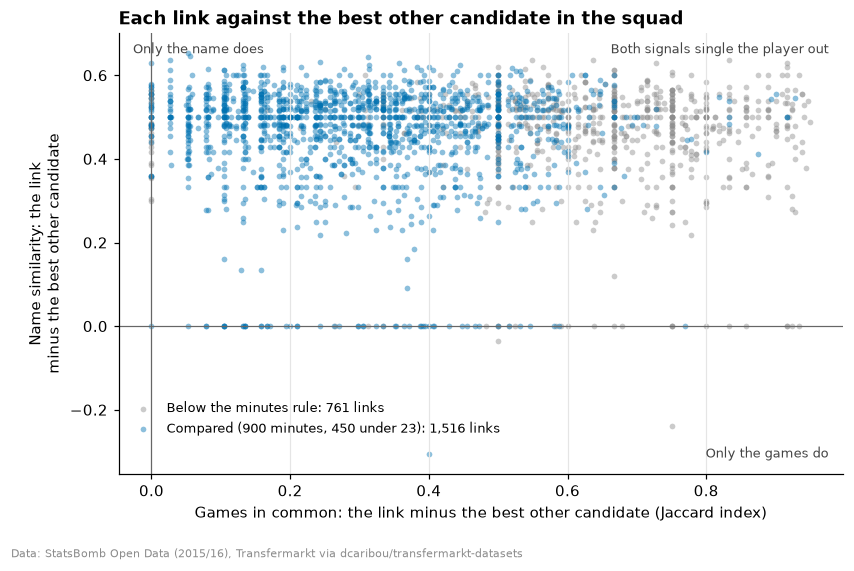

In [54]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
shown = evidence.dropna(subset=["games_margin"])
is_compared = shown.index.get_level_values("sb_player_id").map(compared).to_numpy(bool)
for flag, colour, label in [
    (False, GREY, "Below the minutes rule"),
    (True, OKABE_ITO[0], "Compared (900 minutes, 450 under 23)"),
]:
    d = shown[is_compared == flag]
    ax.scatter(
        d.games_margin, d.name_margin, s=14, color=colour, alpha=0.45, lw=0,
        label=f"{label}: {len(d):,} links",
    )  # fmt: skip
ax.axvline(0, color="#666666", lw=0.8)
ax.axhline(0, color="#666666", lw=0.8)
corners = {
    "Both signals single the player out": (0.98, 0.98, "right", "top"),
    "Only the games do": (0.98, 0.03, "right", "bottom"),
    "Only the name does": (0.02, 0.98, "left", "top"),
}
for text, (x, y, ha, va) in corners.items():
    ax.text(x, y, text, transform=ax.transAxes, ha=ha, va=va, fontsize=8.5, color="#444444")
ax.set_xlabel("Games in common: the link minus the best other candidate (Jaccard index)")
ax.set_ylabel("Name similarity: the link\nminus the best other candidate")
ax.set_title("Each link against the best other candidate in the squad")
ax.grid(axis="both")
ax.legend(loc="lower left", bbox_to_anchor=(0, 0.06), fontsize=8.5)
credit(fig)
plt.show()

Games and name each single the player out for 2,134 of the 2,279 links (93.6%). The games do so
for 97.2% of the links that have Transfermarkt games, the name for 96.4%, and where one signal
ties, the other decides:
- **Games only (80 links).** Another candidate's name matches as well. StatsBomb uses full
  names, so a teammate's shorter Transfermarkt name fits inside them ("Daniel Carvajal Ramos"
  contains "Sergio Ramos" as much as "Daniel Carvajal"), squads share surnames (Touré, Traoré,
  Torres), and nicknames match nothing ("Chicharito", "Juankar").
- **Name only (62 links).** Another candidate played the same games: one-game players (38) and
  ever-presents who played every match next to other ever-presents (24).
- **Neither alone (1 link).** Nampalys Mendy (Nice) played all 38 matches, as did two
  teammates, and shares a surname with Alexandre Mendy; only the linked Transfermarkt player
  matches on both.
- **No 2015/16 Transfermarkt games (2 links).** Markel Susaeta and Rushian Hepburn-Murphy have
  no Transfermarkt appearances that season and are linked by hand
  (`config/player_match_overrides.csv`).

In the figure every link sits clear of its best rival on at least one axis, apart from Mendy at
(0, 0). Ties on games are mostly ever-presents and one-game players, never the middle of the
squad.

### 7.2 Records the matching never used

Both sources record each player's goals, cards and minutes in every game, and the matching never
looked at them. For every player-match in StatsBomb, the linked player's Transfermarkt record of
the same game:

In [55]:
pool_sb = statsbomb_games(con)
pool_sb = pool_sb[pool_sb.competition_id.isin(links.competition_id.unique())]
tm_games = transfermarkt_games(con)
shared = side_by_side(pool_sb, tm_games, links)
print(
    f"{len(pool_sb):,} player-matches in StatsBomb; Transfermarkt has {len(shared):,} of them "
    f"for the linked player ({len(shared) / len(pool_sb):.2%})."
)
per_game = {}
for record, label, tolerance in [
    ("goals", "Goals", 0),
    ("cards", "Cards (yellow and red)", 0),
    ("minutes", "Minutes (within 2)", 2),
]:
    gap = shared[f"sb_{record}"] - shared[f"tm_{record}"]
    differ = gap.abs() > tolerance
    # Differences that cancel out between teammates in the same match: the same goal, card or
    # substitution, given to another player or put at another minute.
    team_match = gap[differ].groupby([shared.match_id[differ], shared.team_id[differ]])
    offset = team_match.transform("size").ge(2) & team_match.transform("sum").abs().le(tolerance)
    per_game[label] = {
        "games that differ": differ.sum(),
        "of which offset by a teammate": offset.sum(),
        "agree (%)": 100 * (1 - differ.mean()),
    }
pd.DataFrame(per_game).T.round(2).astype(
    {"games that differ": int, "of which offset by a teammate": int}
)

42,096 player-matches in StatsBomb; Transfermarkt has 42,056 of them for the linked player (99.90%).


,games that differ,of which offset by a teammate,agree (%)
Goals,18,8,99.96
Cards (yellow and red),89,36,99.79
Minutes (within 2),202,152,99.52


Transfermarkt has 99.90% of the StatsBomb player-matches for the linked player. The 40 missing
are the 29 games of the two links made by hand and 11 single appearances of 11 different
players. In the games both record, goals agree in 99.96% of cases, cards in 99.79% and minutes
within two in 99.52%. Many of the differences cancel out between two teammates in the same
match: a goal or a card credited to the other player, or a substitution put at another minute.
They concern the record of the match, not who played.

**Would these records catch a wrong link?** Each link is checked on five counts the matching
never used, and so is the best other candidate in the squad (the next-highest combined score),
which is what the link would be had it gone wrong:
- **goals** and **cards** over the season, summed over the player's games for the club;
- **minutes**: within two minutes in at least 90% of the games both record;
- **nationality**: StatsBomb's against Transfermarkt's citizenship or country of birth, with
  spellings aligned (StatsBomb's "Congo, (Kinshasa)" is Transfermarkt's "DR Congo");
- **line**: the 2015/16 position group against Transfermarkt's position (goalkeeper, defender,
  midfield, attack). That position is Transfermarkt's latest, a snapshot column: here it only
  checks a link and never describes a player.

A check is left out when it cannot be made: no nationality or position in Transfermarkt, or no
game in common for minutes.

In [56]:
SAME_COUNTRY = {  # StatsBomb and Transfermarkt spellings, after normalize_name
    "bosnia and herzegovina": "bosnia herzegovina",
    "congo brazzaville": "congo",
    "congo kinshasa": "dr congo",
    "lao pdr": "laos",
    "macedonia republic of": "north macedonia",
    "neukaledonien": "new caledonia",
    "the gambia": "gambia",
    "turkey": "turkiye",
    "united states of america": "united states",
    "venezuela bolivarian republic": "venezuela",
}
LINES = {  # position group -> Transfermarkt positions on the same line
    "GK": {"Goalkeeper"},
    "CB": {"Defender"},
    "FB": {"Defender"},
    "CM": {"Midfield"},
    "AM": {"Midfield", "Attack"},
    "W": {"Midfield", "Attack"},
    "CF": {"Attack"},
}
CHECKS = {
    "goals": "Goals in the season",
    "cards": "Cards in the season",
    "minutes": "Minutes within 2 in 90% of shared games",
    "nationality": "Nationality (citizenship or birth)",
    "position": "Line (Transfermarkt's latest position)",
}
sb_season = pool_sb.groupby(["sb_player_id", "team_id"])[["goals", "cards"]].sum()
tm_season = tm_games.groupby(["tm_player_id", "team_id"])[["goals", "cards"]].sum()
sb_people = (
    con.sql("SELECT player_id AS sb_player_id, country FROM players")
    .df()
    .set_index("sb_player_id")
    .join(players.set_index("player_id").position_group.astype(str))
)
tm_people = (
    con.sql(
        "SELECT player_id AS tm_player_id, country_of_citizenship, country_of_birth, position "
        "FROM tm_players"
    )
    .df()
    .set_index("tm_player_id")
)


def country(name: str) -> str:
    n = normalize_name(name)
    return SAME_COUNTRY.get(n, n)


def checks(pairs: pd.DataFrame) -> pd.DataFrame:
    # 1 where a check agrees, 0 where it does not, empty where it cannot be made.
    games = side_by_side(pool_sb, tm_games, pairs)
    close = (games.sb_minutes - games.tm_minutes).abs().le(2)
    minutes_ok = close.groupby([games[k] for k in PAIR_KEYS]).mean().ge(0.9).rename("minutes_ok")
    p = (
        pairs[PAIR_KEYS]
        .join(sb_season, on=["sb_player_id", "team_id"])
        .join(tm_season, on=["tm_player_id", "team_id"], rsuffix="_tm")
        .fillna(0)
        .join(minutes_ok, on=PAIR_KEYS)
        .join(sb_people, on="sb_player_id")
        .join(tm_people, on="tm_player_id")
    )
    sb_country = p.country.map(country, na_action="ignore")
    same_country = sb_country.eq(p.country_of_citizenship.map(country, na_action="ignore")) | (
        sb_country.eq(p.country_of_birth.map(country, na_action="ignore"))
    )
    same_line = pd.Series(
        [pos in LINES[g] for g, pos in zip(p.position_group, p.position, strict=True)], p.index
    )
    return pd.DataFrame(
        {
            "goals": p.goals == p.goals_tm,
            "cards": p.cards == p.cards_tm,
            "minutes": p.minutes_ok,
            "nationality": same_country.where(
                sb_country.notna() & p.country_of_citizenship.notna()
            ),
            "position": same_line.where(
                p.position.isin(["Goalkeeper", "Defender", "Midfield", "Attack"])
            ),
        }
    ).astype(float)


checked = links[links.games_jaccard.notna()]
best_other = (
    others[others.set_index(KEYS).index.isin(checked.set_index(KEYS).index)]
    .sort_values(["score", "tm_player_id"], ascending=[False, True])
    .groupby(KEYS)
    .head(1)
)
link_checks, other_checks = checks(checked), checks(best_other)
display(
    pd.DataFrame(
        {
            "links checked": link_checks.count(),
            "links agree (%)": link_checks.mean() * 100,
            "others checked": other_checks.count(),
            "others agree (%)": other_checks.mean() * 100,
        }
    )
    .rename(index=CHECKS)
    .round(1)
)
link_fails, other_fails = link_checks.eq(0).sum(axis=1), other_checks.eq(0).sum(axis=1)
display(
    pd.DataFrame(
        {"links": link_fails.value_counts(), "best other candidates": other_fails.value_counts()}
    )
    .fillna(0)
    .astype(int)
    .sort_index()
    .rename_axis("checks that disagree")
)

,links checked,links agree (%),others checked,others agree (%)
Goals in the season,2277,99.2,2277,32.6
Cards in the season,2277,96.1,2277,16.4
Minutes within 2 in 90% of shared games,2277,99.1,2261,5.1
Nationality (citizenship or birth),2255,99.8,2245,31.7
Line (Transfermarkt's latest position),2274,95.8,2277,29.7


,links,best other candidates
checks that disagree,,
0,2056,3
1,215,34
2,6,191
3,0,527
4,0,890
5,0,632


The links agree on goals for 99.2% of team-seasons, on minutes for 99.1%, on nationality for
99.8%, on cards for 96.1% and on line for 95.8%. The best other candidates agree on 5% to 33%.
2,056 links (90.3%) agree on all five checks and 215 disagree on one, mostly a card or
Transfermarkt's later position: central midfielders listed as defenders, full-backs listed as
midfielders, wingers turned full-backs. Of the 2,277 best other candidates, 98.4% disagree on
two or more checks. Only 3 agree on all five: one-game players whose rival shared no game with
them, so minutes could not be compared. Six links disagree on two checks:

In [57]:
flagged = checked.loc[link_fails.ge(2)]
failed = link_checks.loc[flagged.index].eq(0)
flagged.assign(
    games=flagged.sb_n_games.astype(int),
    disagree=failed.apply(lambda r: ", ".join(r.index[r]), axis=1),
)[["sb_name", "tm_name", "team_name", "games", "disagree"]].set_index("sb_name").rename_axis(None)

,tm_name,team_name,games,disagree
Corentin Jean,Corentin Jean,Troyes,33,"goals, cards"
Marcus Coco,Marcus Coco,Guingamp,30,"nationality, position"
Grégory Sertic,Grégory Sertic,Bordeaux,1,"minutes, position"
Aloïs Confais,Aloïs Confais,Troyes,14,"cards, position"
Javier Alejandro Mascherano,Javier Mascherano,Barcelona,32,"cards, position"
Aleix Vidal Parreu,Aleix Vidal,Barcelona,9,"minutes, position"


All six are right. Each has the same name and the same games in both sources, and every
disagreement has a plain reason:
- **Corentin Jean** (Troyes, 33 games): one goal and one yellow card that only Transfermarkt
  records; minutes agree in every game.
- **Marcus Coco** (Guingamp): Transfermarkt gives the birthplace, Guadeloupe, as nationality
  (StatsBomb: France); a winger in 2015/16, listed as a right-back now.
- **Grégory Sertic** (Bordeaux, 1 game): substituted at minute 22.8 by StatsBomb's clock and
  minute 25 by Transfermarkt's; a centre-back that day, listed as a defensive midfielder.
- **Aloïs Confais** (Troyes): one yellow card that only StatsBomb records; a full-back in
  StatsBomb, a defensive midfielder in Transfermarkt.
- **Javier Mascherano** (Barcelona): one yellow card that only StatsBomb records; Barcelona's
  centre-back, listed as a defensive midfielder.
- **Aleix Vidal** (Barcelona, 9 games): one game with 18 minutes against 16; a right-back at
  Barcelona, listed as a right winger.

### 7.3 What reaches the back-test

The same evidence by player, for all pool players and for the players Phase 3 compares (900
minutes, or 450 under 23). A player who moved within the pool counts once, with the weaker of
the two links.

In [58]:
by_player = pd.DataFrame(
    {
        "confidence": con.sql("SELECT sb_player_id, confidence FROM player_map")
        .df()
        .set_index("sb_player_id")
        .confidence,
        "signal": evidence.groupby("sb_player_id", observed=True).signal.max(),
        "fails": link_fails.groupby(checked.sb_player_id).max(),
    }
).loc[links.sb_player_id.unique()]
by_player["compared"] = by_player.index.map(compared)
rows = {
    "Players": lambda d: len(d),
    "High-confidence link": lambda d: d.confidence.eq("high").sum(),
    "Medium or low, checked by hand": lambda d: d.confidence.isin(["medium", "low"]).sum(),
    "Manual link (config file)": lambda d: d.confidence.eq("manual").sum(),
    **{f"Signal: {s[0].lower()}{s[1:]}": (lambda d, s=s: d.signal.eq(s).sum()) for s in SIGNALS},
    "Every independent check agrees": lambda d: d.fails.eq(0).sum(),
    "One check disagrees": lambda d: d.fails.eq(1).sum(),
    "Two or more disagree (examined above)": lambda d: d.fails.ge(2).sum(),
}
display(
    pd.DataFrame(
        {
            "all pool players": {k: f(by_player) for k, f in rows.items()},
            "compared players": {k: f(by_player[by_player.compared]) for k, f in rows.items()},
        }
    )
)

catch = other_fails.ge(2)
catch_compared = catch[best_other.sb_player_id.map(compared).to_numpy(bool)]
bound = 3 / catch.mean()
print(
    f"Two or more checks disagree for {catch.mean():.1%} of the best other candidates "
    f"({catch_compared.mean():.1%} for compared players): a wrong link would almost always "
    "be flagged."
)
print(
    f"No flagged link is wrong, so at 95% confidence at most {bound:.1f} of the {len(checked):,} "
    f"checked links are ({bound / len(checked):.2%})."
)
unlinked = con.sql("""
    SELECT count(DISTINCT a.player_id) AS players,
           count(DISTINCT a.player_id) FILTER (WHERE a.player_id NOT IN (
               SELECT tm_player_id FROM player_map)) AS unlinked
    FROM tm_appearances a JOIN match_map mm USING (game_id) JOIN matches m USING (match_id)
    WHERE m.scouting_pool
""").fetchone()
print(
    f"Transfermarkt players who appeared in a pool game: {unlinked[0]:,}, of whom {unlinked[1]} "
    "are not linked."
)
movers = links.groupby("sb_player_id").agg(
    clubs=("team_id", "size"), tm=("tm_player_id", "nunique")
)
movers = movers[movers.clubs > 1]
print(
    f"Players who moved within the pool: {len(movers)}; their two clubs' links, made separately, "
    f"point to the same Transfermarkt player for {movers.tm.eq(1).sum()}."
)

,all pool players,compared players
Players,2176,1436
High-confidence link,2168,1433
"Medium or low, checked by hand",5,2
Manual link (config file),3,1
"Signal: games and name, each on its own",2031,1351
Signal: games only,80,54
Signal: name only,62,29
"Signal: neither alone, both together",1,1
Signal: no 2015/16 Transfermarkt games,2,1
Every independent check agrees,1958,1298


Two or more checks disagree for 98.4% of the best other candidates (99.7% for compared players): a wrong link would almost always be flagged.
No flagged link is wrong, so at 95% confidence at most 3.0 of the 2,277 checked links are (0.13%).
Transfermarkt players who appeared in a pool game: 2,174, of whom 0 are not linked.
Players who moved within the pool: 103; their two clubs' links, made separately, point to the same Transfermarkt player for 103.


Every pool player is linked, and every Transfermarkt player who appeared in a pool game is
linked back. The 103 players who moved within the pool were linked at each club separately, and
the two links always agree.

**How many links can be wrong?** Assume a wrong link looks like the best other candidate. Then
two or more checks would disagree for 98.4% of wrong links (99.7% for compared players), and no
flagged link is wrong. Had W links been wrong, about 0.984 × W of them would have been flagged.
A count that averages more than 3 shows zero less than 5% of the time, so with 95% confidence
0.984 × W ≤ 3: **at most about 3 wrong links in 2,277 (0.13%)**. A wrong link swaps two
players' ages, values and careers, so at this rate the back-test is not affected.

### 7.4 What Transfermarkt sees after 2015/16

The back-test follows players to 2021. Transfermarkt's appearances cover 14 first divisions
(the four pool leagues, the Bundesliga, the Eredivisie and the leagues of Portugal, Turkey,
Belgium, Russia, Greece, Scotland, Ukraine and Denmark), their cups and the European
competitions. Valuations follow players anywhere and name their club at the time (section 4).
In each season from 2016/17 to 2020/21, every pool player is in one of five states:
- played in a covered league;
- at a covered-league club without a league game;
- at a club outside the covered leagues;
- without club or retired;
- not valued that season.

A player's club is the one named on the season's last valuation (1 August to 31 July).

In [59]:
STATUSES = {
    "Played in a covered league": OKABE_ITO[0],
    "At a covered-league club, no league games": OKABE_ITO[4],
    "At a club outside the covered leagues": OKABE_ITO[1],
    "Without club or retired": OKABE_ITO[5],
    "Not valued that season": GREY,
}
con.register("pool_links", links[["sb_player_id", "tm_player_id"]].drop_duplicates())
later = con.sql("""
    WITH seasons AS (SELECT unnest(range(2016, 2021)) AS season),
    league_games AS (
        SELECT a.player_id, g.season, count(*) AS games
        FROM tm_appearances a JOIN tm_games g USING (game_id)
        WHERE g.competition_type = 'domestic_league' GROUP BY ALL),
    covered_clubs AS (
        SELECT DISTINCT season, unnest([home_club_name, away_club_name]) AS club
        FROM tm_games WHERE competition_type = 'domestic_league'),
    clubs AS (  -- the club named on the season's last valuation (1 August to 31 July)
        SELECT v.player_id, s.season, arg_max(v.current_club_name, v.date) AS club
        FROM tm_player_valuations v JOIN seasons s
          ON v.date BETWEEN make_date(s.season, 8, 1) AND make_date(s.season + 1, 7, 31)
        GROUP BY ALL)
    SELECT p.sb_player_id, s.season, coalesce(lg.games, 0) AS games, c.club,
           cc.club IS NOT NULL AS covered_club
    FROM pool_links p CROSS JOIN seasons s
    LEFT JOIN league_games lg ON lg.player_id = p.tm_player_id AND lg.season = s.season
    LEFT JOIN clubs c ON c.player_id = p.tm_player_id AND c.season = s.season
    LEFT JOIN covered_clubs cc ON cc.season = s.season AND cc.club = c.club
    ORDER BY ALL
""").df()
later["status"] = pd.Categorical(
    np.select(
        [
            later.games > 0,
            later.club.isna(),
            later.club.isin(["Without Club", "Unknown", "Retired", "Career break"]),
            later.covered_club,
        ],
        [*list(STATUSES)[:1], list(STATUSES)[4], list(STATUSES)[3], list(STATUSES)[1]],
        list(STATUSES)[2],
    ),
    categories=list(STATUSES),
)
later["season"] = later.season.map(lambda s: f"{s}/{(s + 1) % 100:02d}")
later["compared"] = later.sb_player_id.map(compared)
status_table = pd.concat(
    {
        "All pool players": pd.crosstab(later.status, later.season, normalize="columns"),
        "Compared players": pd.crosstab(
            later[later.compared].status, later[later.compared].season, normalize="columns"
        ),
    }
).mul(100)
display(status_table.round(1).rename_axis(columns=None))

2016/17  2017/18  \
                 status                                                        
All pool players Played in a covered league                    72.6     64.4   
                 At a covered-league club, no league games      2.6      2.1   
                 At a club outside the covered leagues         21.5     25.0   
                 Without club or retired                        0.1      0.3   
                 Not valued that season                         3.2      8.2   
Compared players Played in a covered league                    82.8     75.1   
                 At a covered-league club, no league games      1.0      1.5   
                 At a club outside the covered leagues         14.6     19.2   
                 Without club or retired                        0.1      0.2   
                 Not valued that season                         1.5      4.1   

                                                            2018/19  2019/20  \
                 status                                                        
All pool players Played in a covered league                    55.9     49.8   
                 At a covered-league club, no league games      2.9      2.0   
                 At a club outside the covered leagues         29.9     31.2   
                 Without club or retired                        0.4      1.7   
                 Not valued that season                        10.8     15.3   
Compared players Played in a covered league                    64.8     57.6   
                 At a covered-league club, no league games      2.8      1.7   
                 At a club outside the covered leagues         24.2     26.6   
                 Without club or retired                        0.3      1.3   
                 Not valued that season                         7.8     12.7   

                                                            2020/21  
                 status                                              
All pool players Played in a covered league                    43.5  
                 At a covered-league club, no league games      2.3  
                 At a club outside the covered leagues         32.0  
                 Without club or retired                        1.6  
                 Not valued that season                        20.6  
Compared players Played in a covered league                    51.0  
                 At a covered-league club, no league games      2.5  
                 At a club outside the covered leagues         27.2  
                 Without club or retired                        1.4  
                 Not valued that season                        18.0

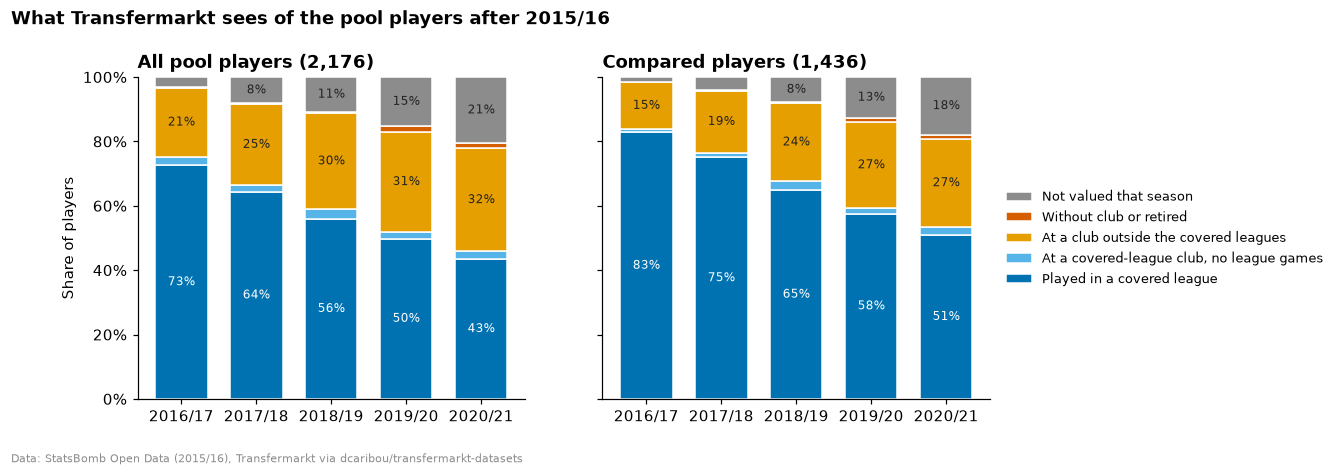

2016/17, most common clubs outside the covered leagues: Newcastle United 21, Norwich City 17, Rayo Vallecano 17, Stade Reims 15, Frosinone Calcio 15, Hellas Verona 14, Levante UD 13, Aston Villa 13
2020/21, most common clubs outside the covered leagues: Watford FC 13, SM Caen 9, CD Leganés 9, Deportivo de La Coruña 9, Sporting Gijón 8, AJ Auxerre 8, Rayo Vallecano 8, SPAL 7


In [60]:
sizes = {
    "All pool players": later.sb_player_id.nunique(),
    "Compared players": later[later.compared].sb_player_id.nunique(),
}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, (who, table) in zip(axes, status_table.groupby(level=0), strict=True):
    table = table.droplevel(0) / 100
    bottom = np.zeros(table.shape[1])
    for status, colour in STATUSES.items():
        ax.bar(
            table.columns, table.loc[status], bottom=bottom, color=colour, width=0.7,
            edgecolor="white", linewidth=1, label=status,
        )  # fmt: skip
        for i, (b, h) in enumerate(zip(bottom, table.loc[status], strict=True)):
            if h >= 0.07:
                text_colour = "white" if colour == OKABE_ITO[0] else "#222222"
                ax.text(
                    i,
                    b + h / 2,
                    f"{h:.0%}",
                    ha="center",
                    va="center",
                    fontsize=8,
                    color=text_colour,
                )
        bottom += table.loc[status].to_numpy()
    ax.set_title(f"{who} ({sizes[who]:,})")
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(False)
axes[0].set_ylabel("Share of players")
axes[1].legend(
    *[list(reversed(x)) for x in axes[1].get_legend_handles_labels()],
    loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8.5,
)  # fmt: skip
fig.suptitle(
    "What Transfermarkt sees of the pool players after 2015/16",
    x=0.01, y=1.04, ha="left", fontweight="bold",
)  # fmt: skip
credit(fig)
plt.show()

outside = later[later.status == list(STATUSES)[2]]
for season in ["2016/17", "2020/21"]:
    top = outside[outside.season == season].club.value_counts().head(8)
    print(
        f"{season}, most common clubs outside the covered leagues:",
        ", ".join(f"{c} {n}" for c, n in top.items()),
    )

A year after the season, 73% of pool players (83% of compared players) played in a covered
league. 21% (15%) were at clubs outside them, mostly the clubs relegated in 2015/16, now in their
second divisions. By 2020/21, 43% (51%) still play in a covered league, 32% (27%) play
elsewhere and 21% (18%) are no longer valued, the decline with age seen in section 4. Fewer
than 2% are listed without club or retired.

So for careers, appearances see only part of the picture. A player who drops into a second
division or moves outside the 14 leagues has no games, minutes or goals on record, but still has
a value and a club. A career outcome built on appearances would treat between a fifth and a
third of players as missing. Values, and the club named on each, reach every player still
valued.

### What section 7 shows

- **Each link rests on two signals that agree.** For 93.6% of the 2,279 pool links, the games
  played and the name each single the player out on their own. Where one ties (shared surnames,
  full names, nicknames; one-game players, ever-presents), the other decides.
- **Records the matching never used confirm the links.** Goals agree in 99.96% of the 42,056
  player-matches both sources record, cards in 99.79% and minutes within two in 99.52%. Many of
  the differences are a goal, a card or a substitution credited to a teammate in the same
  match.
- **A wrong link would show, and none does.** On five independent checks (goals, cards,
  minutes, nationality and line), 98.4% of the best alternative candidates disagree on two or
  more. Only six links do, all right on inspection. At 95% confidence at most about 3 of 2,277
  links are wrong (0.13%).
- **Coverage is complete in both directions.** Every pool player is linked, every Transfermarkt
  player who appeared in a pool game is linked back, and the 103 players who moved within the
  pool were linked to the same player at both clubs.
- **Transfermarkt's appearances lose sight of many players.** Appearances cover 14 first
  divisions. 21% of pool players were outside them a year later, mostly at relegated clubs, and
  32% by 2020/21, while valuations and the club named on them reach every player still valued.

The links can be used as they are. How careers are scored in the back-test (values, the club
named on each valuation, games in covered leagues) is a Phase 3 choice; appearances alone would
miss a fifth to a third of the players.